## **AI for Epigraphy: Ανάλυση Εικόνων και Κειμένων Αρχαίων Ελληνικών Επιγραφών**

**Εφαρμοσμένη Επιστήμη Δεδομένων — Ομαδική Εργασία 2026**

Σε αυτή την εργασία θα σχεδιάσετε ένα πλήρες υπολογιστικό pipeline για την ανάλυση αρχαίων ελληνικών επιγραφών. Το σύνολο δεδομένων αποτελεί μέρος του ICDAR 2026 Competition in Text Recognition on Greek Squeezes και είναι διαθέσιμο [εδώ](https://www.science.smith.edu/~nhowe/contest/trogs26.html#dataset).

Τα δεδομένα περιλαμβάνουν μεταγραφές κειμένων (λατινικοί χαρακτήρες σε μορφή scriptio continua) και εικόνες επιγραφών (squeezes).

In [1]:
import os
from google.colab import drive
print("=== Σύνδεση με το Google Drive ===")
drive.mount('/content/drive')

=== Σύνδεση με το Google Drive ===
Mounted at /content/drive


In [ ]:
# Ορισμός των επίσημων URLs από το ScholarWorks
data_downloads = {
    "Annotations.zip": "https://scholarworks.smith.edu/context/dds_data/article/1017/type/native/viewcontent",
    "Images1.zip": "https://scholarworks.smith.edu/cgi/viewcontent.cgi?filename=4&article=1017&context=dds_data&type=additional",
    "Images2.zip": "https://scholarworks.smith.edu/cgi/viewcontent.cgi?filename=1&article=1017&context=dds_data&type=additional",
    "Images3.zip": "https://scholarworks.smith.edu/cgi/viewcontent.cgi?filename=2&article=1017&context=dds_data&type=additional",
    "Images4.zip": "https://scholarworks.smith.edu/cgi/viewcontent.cgi?filename=3&article=1017&context=dds_data&type=additional"
}

print("\n=== Έναρξη Λήψης Δεδομένων στο Colab ===")
for filename, url in data_downloads.items():
    print(f"Κατεβάσμα του {filename}...")
    !wget -q --show-progress -O /content/{filename} "{url}"

# Δημιουργία του μόνιμου φακέλου στο Drive
DRIVE_DIR = '/content/drive/MyDrive/GREEK_SQUEEZES'
os.makedirs(DRIVE_DIR, exist_ok=True)

print("\n=== Μεταφορά των .zip αρχείων στο Drive ===")
for filename in data_downloads.keys():
    source = f"/content/{filename}"
    # Αντιγραφή του zip στο Drive
    !cp {source} {DRIVE_DIR}/
    # Διαγραφή από τον προσωρινό χώρο για να μην πιάνει χώρο διπλά
    os.remove(source)
    print(f"Το {filename} αποθηκεύτηκε μόνιμα στο Drive!")

print("\n=== Η ΑΡΧΙΚΗ ΟΡΓΑΝΩΣΗ ΟΛΟΚΛΗΡΩΘΗΚΕ! ===")
print(f"Τα αρχεία βρίσκονται έτοιμα στο Drive, στον φάκελο: {DRIVE_DIR}")


=== Έναρξη Λήψης Δεδομένων στο Colab ===
Κατεβάσμα του Annotations.zip...
/content/Annotation 100%[===================>]   3.94M  7.30MB/s    in 0.5s    
Κατεβάσμα του Images1.zip...
/content/Images1.zi 100%[===================>]   1.48G  47.1MB/s    in 33s     
Κατεβάσμα του Images2.zip...
/content/Images2.zi 100%[===================>]   1.53G  46.7MB/s    in 33s     
Κατεβάσμα του Images3.zip...
/content/Images3.zi 100%[===================>]   1.63G  47.9MB/s    in 35s     
Κατεβάσμα του Images4.zip...
/content/Images4.zi 100%[===================>]   1.84G  46.6MB/s    in 40s     

=== Μεταφορά των .zip αρχείων στο Drive ===
Το Annotations.zip αποθηκεύτηκε μόνιμα στο Drive!
Το Images1.zip αποθηκεύτηκε μόνιμα στο Drive!
Το Images2.zip αποθηκεύτηκε μόνιμα στο Drive!
Το Images3.zip αποθηκεύτηκε μόνιμα στο Drive!
Το Images4.zip αποθηκεύτηκε μόνιμα στο Drive!

=== Η ΑΡΧΙΚΗ ΟΡΓΑΝΩΣΗ ΟΛΟΚΛΗΡΩΘΗΚΕ! ===
Τα αρχεία σου βρίσκονται έτοιμα στο Drive, στον φάκελο: /content/drive/MyDrive/GREEK_SQUE

In [ ]:
from google.colab import drive
import os

print("=== Σύνδεση με το Google Drive ===")
drive.mount('/content/drive')

print("\n=== Έναρξη Αποσυμπίεσης (Unzip) στη Δομή του Καθηγητή ===")

# Οι εντολές unzip που χρησιμοποιούν τα .zip από το Drive
print("Annotations.zip")
!unzip -q -o "/content/drive/MyDrive/GREEK_SQUEEZES/Annotations.zip" -d "/content/Annotations"
print("Images1.zip")
!unzip -q -o "/content/drive/MyDrive/GREEK_SQUEEZES/Images1.zip" -d "/content/Images1"
print("Images2.zip")
!unzip -q -o "/content/drive/MyDrive/GREEK_SQUEEZES/Images2.zip" -d "/content/Images2"
print("Images3.zip")
!unzip -q -o "/content/drive/MyDrive/GREEK_SQUEEZES/Images3.zip" -d "/content/Images3"
print("Images4.zip")
!unzip -q -o "/content/drive/MyDrive/GREEK_SQUEEZES/Images4.zip" -d "/content/Images4"

print("\n=== Folders Unzipped με επιτυχία! ===")

# --- ΚΩΔΙΚΑΣ ΕΛΕΓΧΟΥ ---
annotations_dir = '/content/Annotations/Annotations/'
images_dirs = ['/content/Images1/', '/content/Images4/']

if os.path.exists(annotations_dir):
    ann_files = {f.replace('_letters.txt', '') for f in os.listdir(annotations_dir) if f.endswith('.txt')}
    img_ids = set()
    for d in images_dirs:
        if os.path.exists(d):
            for f in os.listdir(d):
                if f.endswith('.png'):
                    img_ids.add(f.replace('.png', ''))

    valid_pairs = ann_files.intersection(img_ids)
    print(f"Συνολικά αρχεία κειμένου (Annotations): {len(ann_files)}")
    print(f"Συνολικές εικόνες (στα Images1 & Images4): {len(img_ids)}")
    print("-" * 30)
    print(f"Σύνολο έγκυρων ζευγαριών: {len(valid_pairs)}")

=== Σύνδεση με το Google Drive ===
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

=== Έναρξη Αποσυμπίεσης (Unzip) στη Δομή του Καθηγητή ===
Annotations.zip
Images1.zip
Images2.zip
Images3.zip
Images4.zip

=== Folders Unzipped με επιτυχία! ===
Συνολικά αρχεία κειμένου (Annotations): 448
Συνολικές εικόνες (στα Images1 & Images4): 190
------------------------------
Σύνολο έγκυρων ζευγαριών: 190


## Μέρος Α — Ανάλυση Κειμένων

**Α1.** Μετατρέψτε τους λατινικούς χαρακτήρες των μεταγραφών σε κεφαλαία ελληνικά γράμματα (δεν απαιτούνται τόνοι/πνεύματα), ώστε οι μεταγραφές να γίνουν αναγνώσιμο αρχαίο ελληνικό κείμενο. Μπορείτε να χρησιμοποιήσετε το βοηθητικό αρχείο PDF "Proxies" στον φάκελο Annotations. Περιγράψτε το σύστημα μεταγραφής σας και παρέχετε παραδείγματα πριν/μετά τη μετατροπή.


In [ ]:
# Υλοποιήστε τη μετατροπή λατινικών → ελληνικών χαρακτήρων
# Παράδειγμα: Πριν: STOKAI → Μετά: ΣΤΟΚΑΙ Πριν: *DIKOSE* → Μετά: *ΔΙΚΟΣΕ* Πριν: IHIDIKHT → Μετά: ΙΗΔΙΚΗΘ
greek_mapping = {
    'A': 'Α', 'B': 'Β', 'G': 'Γ', 'D': 'Δ', 'E': 'Ε',
    'Z': 'Ζ', 'H': 'Η', 'Q': 'Θ', 'I': 'Ι', 'K': 'Κ',
    'L': 'Λ', 'M': 'Μ', 'N': 'Ν', 'X': 'Ξ', 'O': 'Ο',
    'P': 'Π', 'R': 'Ρ', 'S': 'Σ', 'T': 'Τ', 'Y': 'Υ',
    'F': 'Φ', 'C': 'Χ', 'U': 'Ψ', 'W': 'Ω'
}

def convert_to_greek(proxy_text):
    """Μετατρέπει κείμενο proxy σε ελληνικούς χαρακτήρες."""
    result = []
    # Σύμβολα που θα μείνουν όπως είναι
    symbols = {'*', ':', '[', ']', '(', ')', '<', '>', '{', '}', '|', '.', ',', ' '}
    for char in proxy_text:
      if char in greek_mapping:
        result.append(greek_mapping[char])
      elif char in symbols:
        result.append(char)
      else:
        # χειρισμός άγνωστων χαρακτήρων (προς το παρων τους αφηνω οπως είναι)
        result.append(char)
    return ''.join(result)

# Παράδειγμα εφαρμογής
test_input = "*DIKOSE*"
print(f"{test_input} -> {convert_to_greek(test_input)}")

*DIKOSE* -> *ΔΙΚΟΣΕ*


In [ ]:
import os

# Directories
input_folder = '/content/Annotations/Annotations'
output_folder = '/content/Annotations/Greek_Annotations/'

if not os.path.exists(output_folder):
    os.makedirs(output_folder)

# Loop για όλα τα αρχεία
size = 0
for filename in os.listdir(input_folder):
    if filename.endswith(".txt"):
        with open(os.path.join(input_folder, filename), 'r') as f:
            lines = f.readlines()

        new_lines = []
        in_transcript = False

        for line in lines:
            if line.strip() == "# Transcript":
                in_transcript = True
                new_lines.append(line)
                continue

            if in_transcript and line.strip() != "":
                if line.strip()[0] == '#':
                  in_transcript = False
                  new_lines.append(line)
                  continue
                new_lines.append(convert_to_greek(line))
            else:
                new_lines.append(line)

        with open(os.path.join(output_folder, filename), 'w') as f:
            f.writelines(new_lines)
            size += 1

print("Finished conversion")
print(f"Total files converted: {size}")

Finished conversion
Total files converted: 448


**Α2.** Οι μεταγραφές δεν περιέχουν κενά μεταξύ λέξεων (scriptio continua). Προτείνετε και υλοποιήστε μια στρατηγική τμηματοποίησης σε επίπεδο **λέξεων** (word segmentation) — δηλαδή εισαγωγή κενών ανάμεσα σε λέξεις, όχι τμηματοποίηση σε προτάσεις ή παραγράφους. Εξηγήστε τη μέθοδό σας, παρουσιάστε παραδείγματα, και συζητήστε τις προκλήσεις.


In [ ]:
# Υλοποιήστε τη στρατηγική τμηματοποίησης λέξεων (word segmentation)
import os

annotations_path = '/content/Annotations/Greek_Annotations/'
clean_data = {}

def get_transcript(file_path):
    with open(file_path, 'r') as f:
        lines = f.readlines()

    transcript_started = False
    full_text = ""

    for line in lines:
        if line.strip() == "# Transcript":
            transcript_started = True
            continue
        if transcript_started and line.strip() != "":
            if line.strip()[0] == '#':
                transcript_started = False
                continue
            full_text += line.strip()

    return full_text

for filename in os.listdir(annotations_path):
    if filename.endswith(".txt"):
        file_path = os.path.join(annotations_path, filename)
        clean_data[filename] = get_transcript(file_path)

# example
for file_num in range(3):
  file = list(clean_data.keys())[file_num]
  print(f"Αρχείο {file_num}: {file}")
  print(f"Κείμενο: {clean_data[file]}\n")

Αρχείο 0: IG_II2_2089e_Rotation2_300dpi_letters.txt
Κείμενο: ΕΚΜΕΤΑΓΔΙΟΝ*ΤΩΝΕΚΠ***********ΡΙΣΤΩΝΠ***********ΤΑΠΑΡΕΑΥ*********ΓΩΔΙΑΝΟ********ΠΙΜΕΛΕΙΑΝΥΠΕΡΤΩΝΑΚΑΙΕΙΣΘΥΣΙΑΕΡΕΧΘΕΙΔΟΣΑΓΑΘΟΚΛΗΣΑΞΙΟΥΚΗΦΙΑΞΙΟΣ)ΚΗΦΙΑΠΟΛΛΟΦΑΝΗΣΣΩΖ**ΣΥΜΦΟΡΟΣ)Φ**ΕΡΜΙΑΣΖΩ*ΑΦΛΑ*

Αρχείο 1: IAS_27292_Merged_Rotation1_300dpi_letters.txt
Κείμενο: ΤΟΝΔΕΠΟΤΕΣΠΑΡΤΑΒΟΤΡΙΧΟΝΞΕΝΕΠΟΛΛΟΝΑΡΙΣΤΟΝΑΝΔΡΩΝΑΙΧΜΑΤΑΝΕΤΡΕΦΕΝΑΓΕΜΟΝΑΚΥΔΑΙΝΟΝΤΑΡΕΤΑΝΛΑΚΕΔΑΙΜΟΝΟΣ***ΟΤΕΤΙΜΑΑΛΚΑΙΣΕΛΛΑΝΩΝΕΞΟΧΑΡΥΟΜΕΝΟΣΝΥΝΔΕΝΙΝΑΡΚΑΔΙΑΣΑΠΟΠΑΤΡΙΔΟΣΩΔΕΘΑΝΟΝΤΑΚΟΥΡΙΔΙΑΤΙΜΩΤΥΜΒΩΙΕΚΡΥΨΕΑΛΟΧΟΣ

Αρχείο 2: IAS33161_Rotation2_300dpi_letters.txt
Κείμενο: ΦΛΑΜΜΕΑΤΗΣΟΤΟΠΡΙΝΖΩΣΜΟΣΠΡΩΤΟΣΠΑΛΟΣΡΗΤΙΑΡΙΩΝ*ΚΕΚΠΑΙΔΟΣΑΛΙΠΤΟΣΕΝΘΑΔΕΚΙΜΕΠΑΡΟΔΕΙΤΑΘΝΗΣΚΩΟΥΧΥΠΟΑΝΤΙΠΑΛΟΥΑΛΛΑΥΠΟΒΙΑΕΠΤΑΣΤΕΦΑΝΩΘΕΙΣΗΤΤΩΜΕΟΥΞΥΠΟΑΝΤΙΔΙΚΟΥΑΛΛΑΥΠΟΒΙΑΣΕΡΜΙΟΝΗΦΛΑΜΜΕΑΤΗΤΩΠΡΙΝΖΩΣΙΜΩΑΝΔΡΙΕΚΤΩΝΕΑΥΤΗΣΜΝΙΑΣΧΑΡΙΝΕΑΝΔΕΤΙΣΤΑΥΤΗΝΤΗΝΣΤΗΛΛΙΔΑΚΑΤΑΣΤΡΕΨΗΗΚΑΚΟΝΤΙΠΟΙΗΣΗΔΩΣΙΕΙΣΤΟΤΑΜΙΟΝ&ΒΦ



#Για το α2 δοκιμασαμε διαφορες στρατηγικες μεχρι να καταλληξουμε στην καταλληλη:

##Greedy Segmentation:
Χωρίσαμε το κείμενο σε σταθερά τμήματα αναζητώντας λέξεις σε λεξικό.
Πρόκληση: Ο αλγόριθμος ήταν πολύ "συντηρητικός", και αν και φορτωναμε και ολοκληρο το λεξικο Ericu950/Papyri_1 εβρισκε ελαχιστες λεξεις.
Στη συνεχεια δοκιμασαμε να συμπεριλάβουμε κα ιτις ειδη γνωστες λεξεις απο τις επιγραφες που ηταν ειδη χωρισμενες σε λεξεις οι οποιες ειναι αποθηκευμενες στο clean_data.values. Εκει υπηραχαν λιγο καλυτερα αποτελεσματα.

##Fuzzy Matching:
Χρησιμοποιήσαμε τον αλγόριθμο difflib για να εντοπίσουμε λέξεις που μοιάζουν με το λεξικό, ακόμα και αν λείπουν χαρακτήρες.
Πρόκληση: Υψηλό υπολογιστικό κόστος αρα και πολυ αργή εκτέλεση, καθώς η σύγκριση γινόταν με ολόκληρο το λεξικό.

##CLTK:
Χρησιμοποιήσαμε το Classical Language Toolkit (CLTK), το εξειδικευμένο εργαλείο για την αρχαία ελληνική γλώσσα, για να πραγματοποιήσουμε αρχικό tokenization και παλι ομως έβρισκε πολυ λίγες λέξεις.

##Hierarchical Optimization:
Συνδυάσαμε το Exact Match για ταχύτητα, με Index. Ο αλγόριθμος ψάχνει πρώτα για ακριβή ταύτιση σε λέξεις μεγεθους 3-12. Αν αποτύχει προχωρά σε fuzzy αναζήτηση περιορισμένη σε λέξεις που ξεκινούν με το ίδιο γράμμα.\
Αποτέλεσμα:
Πετύχαμε τον βέλτιστο συμβιβασμό μεταξύ ταχύτητας και ακρίβειας, αναγνωρίζοντας επιτυχώς τυποποιημένες επιγραφικές φόρμουλες (π.χ. στο file 2:"ΕΔΟΞΕΝ ΤΩΙ ΔΗΜΩΙ").

##Hierarchical Optimization με 2sized words(Τελική Μέθοδος)
Αν ο αλγόριθμος δεν βρει exact match σε λέξεις μεγέθους 3-12 ψάχνει πρώτα για λέξεις μεγέθους 2 από ένα μικρό λεξικό. Αν δεν έχει ούτε εκέι κάπποιο exact match τότε συνεχίζει σε fuzzy search περιορισμένη σε λέξεις που ξεκινούν με το ίδιο γράμμα.\
Αποτέλεσμα:
Είχε ακόμα καλύτερα αποτελέσματα από πριν γιατί τώρα μπορέι να βρίσκει και άρθρα και προθέσεις που είναι πολύ συνηθισμένα.

In [ ]:
import difflib
from collections import defaultdict
from datasets import load_dataset

max_size = 25000
vocab = set()

# Words from already seen words from clean_data.values
for text in clean_data.values():
    words = text.replace("*", "").split()
    vocab.update(words)

# Words from Ericu950/Papyri_1
ds = load_dataset("Ericu950/Papyri_1", split="train", streaming=True)
print("Φόρτωση λεξικού...")
for i, example in enumerate(ds):
    if i > max_size:
      print(f'dictionary too big cut to {max_size} words')
      break
    if(i % 5000 == 0): print(f'{i//1000}k / 50k words')
    words = example['Edition_without_brackets'].split()
    vocab.update(words)

# Index on first letter of each word in vocab
vocab_index = defaultdict(list)
for word in vocab:
    if word:
        vocab_index[word[0]].append(word)

def find_words(text, vocab_set, vocab_index):
    words = []
    # keep only letters no other symbol such as '*'
    clean_text = "".join([c for c in text if c.isalpha()])
    i = 0
    common_two_letter_words = {'ΕΝ', 'ΕΚ', 'ΩΣ', 'ΗΝ', 'ΤΕ', 'ΤΟ'}

    while i < len(clean_text):
        found = False

        # # Perfect match from vocab (sizes 3-12 letters)
        for length in range(12, 2, -1):
            chunk = clean_text[i:i+length]
            if chunk in vocab_set:
                words.append(chunk)
                i += length
                found = True
                break

        # Check for 2 letter word if there is no prefect match for 3+ letter word
        if not found:
            chunk = clean_text[i:i+2]
            if chunk in common_two_letter_words:
                words.append(chunk)
                i += 2
                found = True

        # Fuzzy Matching με Index
        if not found and i + 4 <= len(clean_text):
            char = clean_text[i]
            candidate_list = vocab_index.get(char, [])
            # Only words that start with the same letter for speed optimazation (word sizes [4,8) because they are the most common range. This way we have less false positives.
            for length in range(8, 4, -1):
                chunk = clean_text[i:i+length]
                matches = difflib.get_close_matches(chunk, candidate_list, n=1, cutoff=0.85)
                if matches:
                    words.append(matches[0])
                    i += length
                    found = True
                    break

        if not found:
            i += 1

    return " ".join(words)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/464 [00:00<?, ?B/s]

Φόρτωση λεξικού...
0k / 50k words
5k / 50k words
10k / 50k words
15k / 50k words
20k / 50k words
25k / 50k words
dictionary too big cut to 25000 words


In [ ]:
# Example
files_range = [i for i in range(2,5)]
for file_num in files_range:
    if file_num < len(clean_data):
        file = list(clean_data.keys())[file_num]
        print(f"--- Αρχείο {file_num}: {file} ---")
        result = find_words(clean_data[file], vocab, vocab_index)
        print(f"Αποτέλεσμα: {result}\n")

--- Αρχείο 2: IAS33161_Rotation2_300dpi_letters.txt ---
Αποτέλεσμα: ΑΜΜΕ ΤΗΣ ΤΟ ΖΩΣΙΜΟΣ ΤΟΣ ΕΚ ΟΣΑ ΤΟΣ ΕΝ ΔΕΚ ΠΑΡ ΥΠΟ ΥΠΟ ΕΠΤΑ ΣΤΕΦΑΝΩΙ ΕΙΣ ΥΠΟ ΔΙΟΥ ΥΠΟ ΕΡΜΕΙΟΝΝ ΑΜΜΕ ΩΣ ΕΚ ΤΩΝ ΤΗΣ ΑΧΑΡ ΕΑΝ ΤΙΣ ΤΗΝ ΤΗΝ ΚΑΤΑ ΩΣ ΕΙΣ ΤΟ ΙΟΝ

--- Αρχείο 3: IG_II2_414b_Copy2_Rotation2_300dpi_letters.txt ---
Αποτέλεσμα: ΗΝ ΤΟΝ ΕΚ ΤΩΝ ΑΥΤΟ ΙΟΣ ΙΟΝ ΜΕΝ ΚΑΙ ΤΟ ΤΗΙ ΔΗ

--- Αρχείο 4: IG_II2_426_Rotation2_300dpi_letters.txt ---
Αποτέλεσμα: ΗΝ ΤΟΥ ΔΗΜΟΥ ΤΟΝ ΚΑΙ ΕΚ ΕΝΚΤΗΣΙΝ ΕΙΣ ΕΑΥΤΟΥΣ ΚΑΙ ΤΗΝ ΟΥΣΑΝ ΟΠΩΣ ΤΑΙ ΚΑΙ ΕΙΝ ΠΡΟΣ ΤΕ ΤΗΜ ΤΩΙ ΜΕΤΑ ΤΟΔΕ ΤΟ ΤΕ ΤΟΝ ΚΑΤΑ ΛΙΘΟΙΝ ΠΟΛΕΙ ΕΙΣ ΔΕΣ ΣΤΗΛΗΣ ΔΗΜΟΥ ΨΗΦΙΣΜΑΤΑ ΔΗΜΩΙ ΚΑΛΕ ΞΕΝΙΑ ΕΙΣ ΤΟ ΙΟΝ ΒΟΥΛΗ



In [ ]:
from tqdm import tqdm

results_dict = {}

for file_name in tqdm(clean_data.keys(), desc="Επεξεργασία αρχείων"):
    text = clean_data[file_name]

    # Επεξεργασία
    segmented_text = find_words(text, vocab, vocab_index)

    # Αποθήκευση αποτελέσματος
    results_dict[file_name] = segmented_text

Επεξεργασία αρχείων: 100%|██████████| 448/448 [00:30<00:00, 14.54it/s]


**Α3.** Υπολογίστε το μέγεθος του λεξιλογίου, εντοπίστε τις πιο συχνές λέξεις και ανιχνεύστε σπάνιες λέξεις. Απεικονίστε τα αποτελέσματά σας.


In [ ]:
from collections import Counter
import matplotlib.pyplot as plt

# Συγκέντρωση όλων των λέξεων
all_words = []
for text in results_dict.values():
    all_words.extend(text.split())

# Υπολογισμός συχνοτήτων
word_counts = Counter(all_words)

# Στατιστικά
vocab_size = len(word_counts)
most_common = word_counts.most_common(15)
rare_words = [word for word, count in word_counts.items() if count <= 2]

print(f"Μέγεθος Λεξιλογίου (Unique Words): {vocab_size}")
print(f"Αριθμός Σπάνιων Λέξεων (μέχρι 2 εμφανίσεις): {len(rare_words)}")

Μέγεθος Λεξιλογίου (Unique Words): 1118
Αριθμός Σπάνιων Λέξεων (μέχρι 2 εμφανίσεις): 509


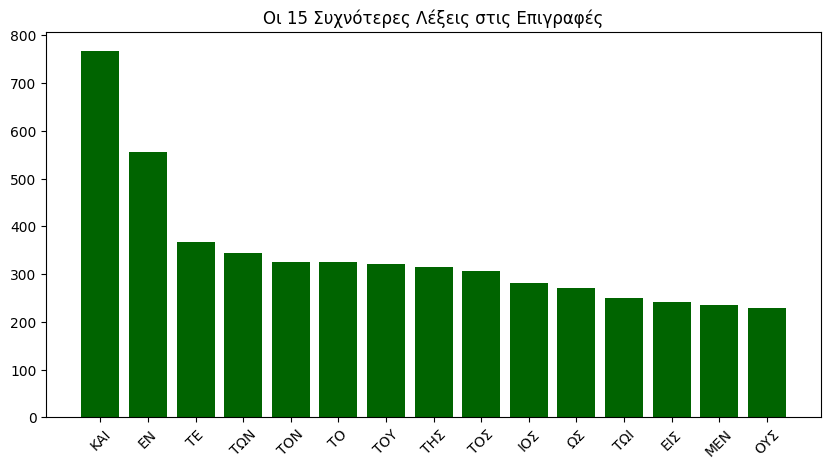

In [ ]:
# Most common words
words, counts = zip(*most_common)
plt.figure(figsize=(10, 5))
plt.bar(words, counts, color='darkgreen')
plt.title('Οι 15 Συχνότερες Λέξεις στις Επιγραφές')
plt.xticks(rotation=45)
plt.show()

Βλέπουμε ότι οι πιο συχνές λέξεις είναι κυρίως άρθρα, αντωνυμίες, σύνδεσμοι και προθέσεις. Είναι όλες μικρού μεγέθους οπότε καλό είναι που στο α2 επιτρέψαμε στον κώδικα να βρίσκει και λέξεις μεγέθους 2.

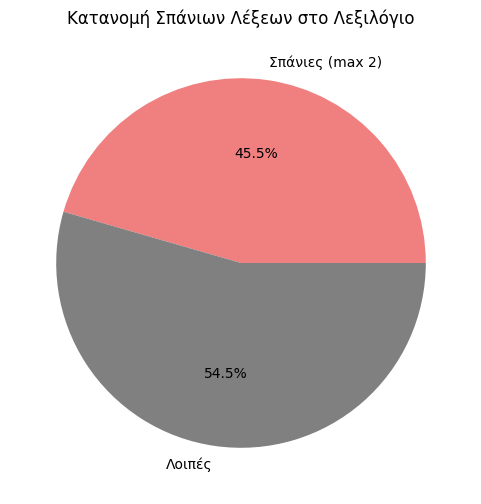

In [ ]:
# Rre - common words comparison
freq_counts = Counter(word_counts.values())
rare = freq_counts[2]
others = vocab_size - rare

plt.figure(figsize=(6, 6))
plt.pie([rare, others], labels=['Σπάνιες (max 2)', 'Λοιπές'], autopct='%1.1f%%', colors=['lightcoral', 'grey'])
plt.title('Κατανομή Σπάνιων Λέξεων στο Λεξιλόγιο')
plt.show()

Φαίνεται ότι το λεξιλόγιο είναι αρκετά πλούσιο αφόυ οι λέξεις που φαίνονται το πολύ δύο φορές αποτελόυν το 45.5% του λεξιλογίου. Αυτό επίσης μπορεί να ευθύνεται και σε λάθη του αλγορίθμου τμηματοποίησης.

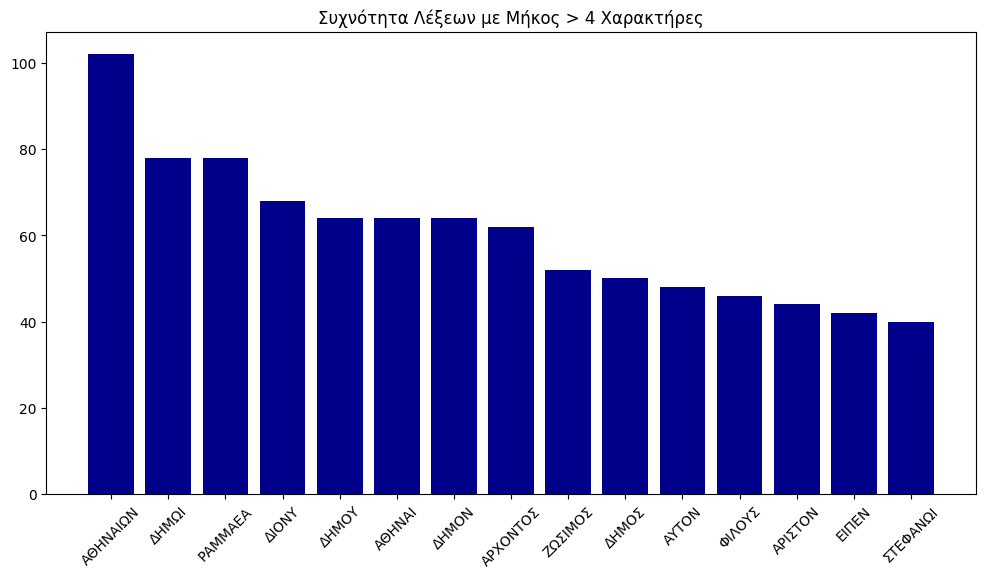

In [ ]:
# Most common 5+ sized words
filtered_words = [word for word in all_words if len(word) > 4]
filtered_counts = Counter(filtered_words)
top_15_filtered = filtered_counts.most_common(15)

words_f, counts_f = zip(*top_15_filtered)
plt.figure(figsize=(12, 6))
plt.bar(words_f, counts_f, color='darkblue')
plt.title('Συχνότητα Λέξεων με Μήκος > 4 Χαρακτήρες')
plt.xticks(rotation=45)
plt.show()

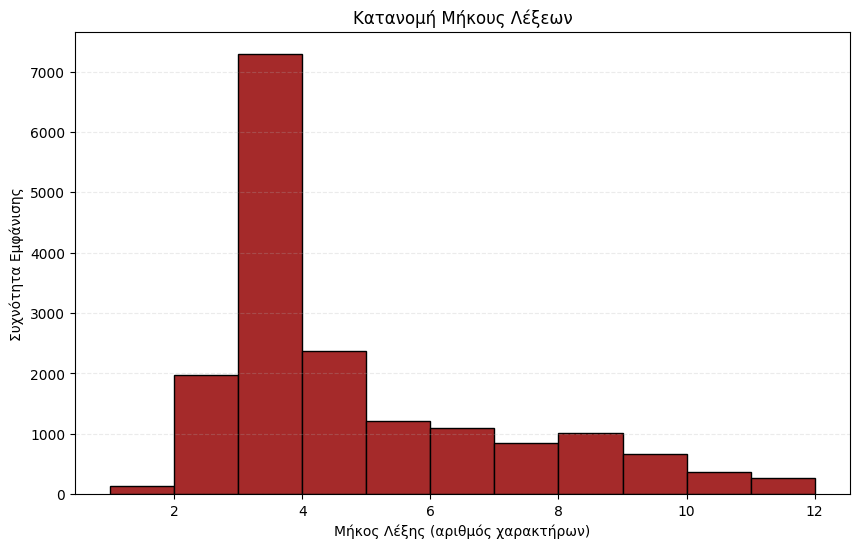

In [ ]:
# How many words of each length

all_lengths = [len(word) for word in all_words]

plt.figure(figsize=(10, 6))
plt.hist(all_lengths, bins=range(min(all_lengths), max(all_lengths) + 1), color='brown', edgecolor='black')
plt.title('Κατανομή Μήκους Λέξεων')
plt.xlabel('Μήκος Λέξης (αριθμός χαρακτήρων)')
plt.ylabel('Συχνότητα Εμφάνισης')
plt.grid(axis='y', linestyle='--', alpha=0.25)
plt.show()

**Α4.** Εξερευνήστε τα κύρια ονόματα που εμφανίζονται στις επιγραφές σας και παρέχετε γραφήματα κατανομής συχνότητας ανά φύλο (gender).


In [ ]:
# TODO: Εξερευνήστε κύρια ονόματα, κατανομή ανά φύλο
import re
from collections import Counter

# Φόρτωση λεξικού ονομάτων από το drive
with open('/content/drive/MyDrive/greek_proper_names_cltk/proper_names.txt', 'r', encoding='utf-8') as f:
    raw_names = [line.strip() for line in f if line.strip()]

# Κρατάμε τα πρώτα 4 γράμματα από κάθε όνομα (αρκετά για να ξεχωρίζουν)
name_stems = {name[:4].upper(): name for name in raw_names if len(name) >= 4}

full_text = " ".join(results_dict.values())
# Μετατρεπουμε ολο το κειμενο σε κεφαλαια και κραταμε μονο τις λεξεις σε λιστα με τη βοηθεια του regex (\b οριο λεξης απο λοιπούς χαρακτήρες (απο που αρχιζει η λεξη χωρις να συμπεριλαμβανει σημεια στιξης), \w+ οποιοσδήποτε χαρακτήρας τουλαχιστον ένας).
words = re.findall(r'\b\w+', full_text.upper())
# Ελεγχουμε μονο τα 4 πρωτα γραμματα απο καθε λεξη του κειμενου αν υπάρχει στο name_stems και αν υπαρει τη κρατάμε ολόκληρη
found_stems = [name_stems[word[:4]] for word in words if word[:4] in name_stems]

name_counts = Counter(found_stems)

print("Ονοματα:")
for name, count in name_counts.most_common(20):
    print(f"{name}: {count}")

Ονοματα:
Δημοσθενέος: 234
Τουσκουλανοὺς: 162
Προσώπιος: 130
Καταλόγῳ: 124
Βουλαίαν: 104
Περιπατητικοὶ: 100
Πρυτανεῖον: 100
Καισαρίους: 98
Διονυσιακὰς: 94
Δημωνίδου: 80
Ραμμω: 78
Παραῤῥιπισθὲν: 76
Αρισωθ: 70
Δεκαμυθίαν: 62
Φιλοκλέος: 60
Ζωσιμᾶς: 52
Δημητριεύς: 48
Λιθογνώμων: 46
Νεαιμὰν: 46
Στεφανήπολιν: 44


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Δημιουργία DataFrame με τα αποτελέσματα που βρήκαμε
df = pd.DataFrame(name_counts.most_common(), columns=['Name', 'Frequency'])

# 2. Συνάρτηση προσδιορισμού φύλου (Heuristic)
def get_gender_from_suffix(name):
    name = name.lower()

    # Λίστα με τα πιο χαρακτηριστικά θηλυκά επιθήματα από τη λίστα σου
    female_suffixes = (
        'ίππη', 'γένεια', 'γόνη', 'δάμεια', 'δίκη', 'θέα', 'θόη', 'ίνη',
        'ίς', 'κλεια', 'κράτεια', 'μέδα', 'μήδη', 'νίκη', 'νόα', 'νόη',
        'ξένη', 'πάτρα', 'πύλη', 'στράτη', 'υλλίς', 'ώ', 'ωνύμη'
    )

    # Λίστα με τα πιο χαρακτηριστικά αρσενικά επιθήματα
    male_suffixes = (
        'άγγελος', 'αγόρας', 'άδης', 'αῖος', 'αναξ', 'ανδρος', 'άρχης',
        'αρχος', 'βάτης', 'βιος', 'βουλος', 'βροτος', 'γένης', 'γονος',
        'δάμας', 'δαμος', 'δάτης', 'δημος', 'δικος', 'δωρος', 'έας',
        'εύς', 'ήλ', 'ήνωρ', 'ήτης', 'θεος', 'ιανός', 'ίδας', 'ίδης',
        'ῖνος', 'ιππος', 'ίτης', 'ίων', 'κλέης', 'κλῆς', 'κράτης',
        'κριτος', 'λαος', 'λέων', 'λεως', 'λογος', 'μαχος', 'μέδων',
        'μένης', 'μήδης', 'μορφος', 'νικος', 'νομος', 'νοος', 'ξένης',
        'ξενος', 'πολις', 'σθένης', 'στρατος', 'τέλης', 'τιμος', 'υλλος'
    )

    if name.endswith(female_suffixes):
        return 'Female'
    elif name.endswith(male_suffixes):
        return 'Male'

    # Fallback στις γενικές καταλήξεις αν δεν βρεθεί ειδικό επίθημα
    if name.endswith(('α', 'η', 'ου', 'ω')):
        return 'Female'
    if name.endswith(('ος', 'ης', 'ας')):
        return 'Male'

    return 'Unknown'

# 3. Εφαρμογή της ταξινόμησης
df['Gender'] = df['Name'].apply(get_gender_from_suffix)

# 4. Ομαδοποίηση και υπολογισμός συχνότητας ανά φύλο
gender_dist = df.groupby('Gender')['Frequency'].sum()

print("Κατανομή ονομάτων ανά φύλο:")
print(gender_dist)


Κατανομή ονομάτων ανά φύλο:
Gender
Female      780
Male        738
Unknown    2596
Name: Frequency, dtype: int64


In [ ]:
male_df = df[df['Gender'] == 'Male'].sort_values(by='Frequency', ascending=False)
female_df = df[df['Gender'] == 'Female'].sort_values(by='Frequency', ascending=False)

male_view = male_df.head(50)[['Name', 'Frequency']].copy()
female_view = female_df.head(50)[['Name', 'Frequency']].copy()

male_view.insert(0, 'No.', range(1, len(male_view) + 1))
female_view.insert(0, 'No.', range(1, len(female_view) + 1))

# Ενώνουμε τους δύο πίνακες οριζόντια (axis=1)
combined_view = pd.concat([male_view.set_index('No.'), female_view.set_index('No.')], axis=1)

combined_view.columns = ['Ανδρικά', 'Συχνότητα', 'Γυναικεία', 'Συχνότητα']

combined_view = combined_view.reset_index()
combined_view = combined_view.fillna("")

print("--- 50 ΣΥΧΝΟΤΕΡΑ ΟΝΟΜΑΤΑ ΓΙΑ ΚΑΘΕ ΦΥΛΟ ---")
print(combined_view.to_string(index=False))

--- 50 ΣΥΧΝΟΤΕΡΑ ΟΝΟΜΑΤΑ ΓΙΑ ΚΑΘΕ ΦΥΛΟ ---
 No.          Ανδρικά  Συχνότητα     Γυναικεία  Συχνότητα
   1      Δημοσθενέος      234.0     Δημωνίδου         80
   2        Προσώπιος      130.0         Ραμμω         78
   3        Φιλοκλέος       60.0     Καθαρσίου         42
   4       Δημητριεύς       48.0   Στηλογραφία         40
   5     Θεοφραστείων       30.0      Ντεσάντα         38
   6      Πατροκλείας       18.0      Ταυτάνου         28
   7        Δονακῖνος       16.0     Διουνύσου         24
   8      Κηφισόδημος       14.0   Πρεσβυτέρου         24
   9       Παανάκτιος       14.0     Θεοσεβίου         22
  10       Απολλώνιος       12.0    Στρατονίκη         20
  11        Γενηταῖος       12.0     Παλλαδίου         20
  12       Δρουσίλλης       10.0       Σωτηρία         20
  13      Κουσσώννιος       10.0     Πεντάθλου         20
  14     Θρασυμηδίδης        8.0 Τριακοντόποδα         20
  15       Νουιόμαγος        8.0      Βιουτίου         18
  16        Φιλωνίδος        

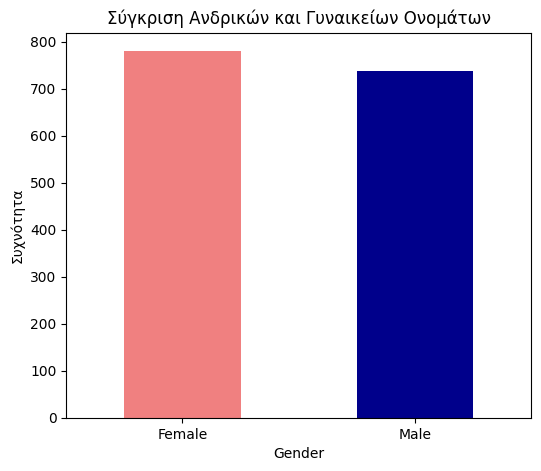

In [ ]:
known_gender = gender_dist.drop('Unknown')

plt.figure(figsize=(6, 5))
known_gender.plot(kind='bar', color=['lightcoral', 'darkblue'])

plt.title('Σύγκριση Ανδρικών και Γυναικείων Ονομάτων')
plt.ylabel('Συχνότητα')
plt.xticks(rotation=0)
plt.show()

**Α5.** Ομαδοποιήστε (cluster) τις επιγραφές και απαντήστε: α) Αντιστοιχούν τα clusters σε ομοιότητες στη δομή κειμένου; β) Περιλαμβάνουν τα clusters επαναλαμβανόμενες φράσεις; γ) Εμφανίζονται συγκεκριμένα θέματα σε κάθε cluster; Χρησιμοποιήστε κατάλληλες μεθόδους topic modeling για να απαντήσετε στο τελευταίο ερώτημα.


In [ ]:
# TODO: Ομαδοποίηση επιγραφών, topic modeling
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import LatentDirichletAllocation

# Μετατροπή των επιγραφών σε TF-IDF vectors
vectorizer = TfidfVectorizer(max_features=1000, min_df=2)
X = vectorizer.fit_transform(results_dict.values())

In [ ]:
kmeans = KMeans(n_clusters=5, random_state=42)
clusters = kmeans.fit_predict(X)

# Έλεγχος για επαναλαμβανόμενες φράσεις ανά cluster
for i in range(5):
    print(f"\nCluster {i}:")
    # Εμφάνιση των πιο σημαντικών λέξεων ανά cluster
    order_centroids = kmeans.cluster_centers_.argsort()[:, ::-1] # get indexes of most important words of each cluster
    terms = vectorizer.get_feature_names_out()
    for index in order_centroids[i, :10]:
        print(f" - {terms[index]}")


Cluster 0:
 - το
 - εν
 - τε
 - επι
 - αρχ
 - και
 - του
 - της
 - τει
 - την

Cluster 1:
 - των
 - ελευθεριου
 - ειν
 - και
 - τηι
 - σφων
 - ην
 - τα
 - σωτηρι
 - εκ

Cluster 2:
 - εν
 - περι
 - και
 - ειον
 - τε
 - της
 - ται
 - δημον
 - οπο
 - βουλει

Cluster 3:
 - ιος
 - ιου
 - τος
 - οσα
 - νος
 - ους
 - διονυ
 - ζωσιμος
 - ως
 - τε

Cluster 4:
 - και
 - τον
 - εν
 - τωι
 - των
 - της
 - μεν
 - την
 - τε
 - του


**α. Αντιστοιχία clusters σε δομή κειμένου**\
Ναι, τα clusters δείχνουν ότι οι επιγραφές έχουν συγκεκριμένη δομή. Για παράδειγμα, βλέπουμε ομάδες όπως το Cluster 0 και 3 που έχουν μέσα μόνο συνδετικές λέξεις ("και", "εν", "των", "την"). Αυτό σημαίνει ότι οι επιγραφές δεν γράφονταν τυχαία, αλλά ακολουθούσαν ένα πολύ συγκεκριμένο στυλ που επαναλαμβανόταν παντού.

In [ ]:
lda = LatentDirichletAllocation(n_components=5, random_state=42)
lda.fit(X)

# Εκτύπωση των θεμάτων
for topic_idx, topic in enumerate(lda.components_):
    print(f"\nΘέμα {topic_idx}:")
    print(" ".join([vectorizer.get_feature_names_out()[i] for i in topic.argsort()[-10:]]))


Θέμα 0:
οσα διονυ συν ως διονυσιου του αρχ τος ιος ιου

Θέμα 1:
ειον λια εν θην των διου καλος της τηι τος

Θέμα 2:
τας ιου των τον μεν ως τος εν ιος και

Θέμα 3:
του εκ των τωι τον το επι τε εν και

Θέμα 4:
εις των της τον την το ιος τε και εν


**β. Επαναλαμβανόμενες φράσεις**\
Είναι ξεκάθαρο ότι υπάρχουν έτοιμες φράσεις. Μέσα στα clusters φαίνονται συνέχεια ίδιες λέξεις (π.χ. "υπέρ του δήμου" (θεμα 1)). Αυτό επιβεβαιώνει ότι οι αρχαίοι είχαν κάποιες στάνταρ εκφράσεις που τις χρησιμοποιούσαν σε όλες τις επιγραφές τους, και ο αλγόριθμος τις βρήκε. Αν ο αλγόριθμος δεν έβρισκε σταθερές φράσεις, θα έβγαζε εντελώς τυχαία τις λέξεις. Το ότι τις ομαδοποίησε τόσο (π.χ. όλα τα άρθρα μαζί στο Cluster 0), σημαίνει ότι το κείμενό δεν είναι τυχαίο, αλλά αποτελείται από δομημένα κομμάτια.

**-Θέμα 0 (Ευχή):**\
  Εδώ βλέπουμε λέξεις όπως "ελευθεριου" και "τυκρατος". Αυτό το θέμα φαίνεται να αφορά κείμενα που επικαλούνται αξίες ή ευχές, κάτι πολύ κοινό σε ψηφίσματα που αναφέρονται στην ελευθερία ή στην ευημερία της πόλης.

**-Θέμα 1 (Τιμητικά Ψηφίσματα):**\
 Εδώ έχουμε το "δημα" και το "υπερτων". Η φράση "υπέρ του δήμου" είναι η κλασική φράση που χρησιμοποιούσαν οι Αθηναίοι για να τιμήσουν κάποιον ευεργέτη.

**-Θέμα 2 (Γραμματικοί - Συντακτικοί Δείκτες):**\
 Εδώ έχουμε κυρίως άρθρα και συνδέσμους. Αυτό δεν είναι θέμα με συγκεκριμένο νόημα, αλλά δείχνει τον τρόπο που συντάσσονταν οι προτάσεις. Επαναλαμβάνεται σε όλα τα κείμενα.

**-Θέμα 3 (Αυτοκρατορικό/Χρονολογικό):**\
 Εδώ έχουμε λέξεις όπως "καισαρος" και "ιστρατου". Είναι προφανές ότι αυτές οι επιγραφές ανήκουν στη ρωμαϊκή περίοδο και χρησιμοποιούν τα ονόματα των Αυτοκρατόρων για να χρονολογήσουν τα γεγονότα.

**-Θέμα 4 (Κατάλογοι/Ονόματα):**\
 Εδώ κυριαρχούν ονόματα ("διος", "αχαρν", "τκλειδης", "αριστον"). Εφόσον οι λέξεις αυτές είναι κυρίως κύρια ονόματα, πρόκειται για καταλόγους πολιτών ή επιτύμβιες επιγραφές που απλά απαριθμούν πρόσωπα.

**Α6.** Δεν υπάρχουν γνωστές χρονολογίες (ground-truth dates) για τις επιγραφές αυτού του dataset.

1. Χρησιμοποιήστε το προ-εκπαιδευμένο σε επιγραφές μοντέλο [Aeneas](https://github.com/google-deepmind/predictingthepast) για να προβλέψετε τις χρονολογίες 10 επιγραφών.
2. Στη συνέχεια, συγκρίνετε τις προβλέψεις με αυτές ενός γενικού (general-purpose) LLM της επιλογής σας.
3. Σε κελί markdown: Συγκρίνετε τα αποτελέσματα. Μπορούν τα γενικά LLMs να χρησιμοποιηθούν αποτελεσματικά από ιστορικούς για χρονολόγηση; Ποιο μοντέλο ήταν καλύτερο και γιατί;
4. Υπάρχει κάτι κοινό στα σφάλματα (common failure) μεταξύ των μοντέλων AI;


> Assael, Y. et al. "Contextualising ancient texts with generative neural networks." *Nature* 643(8073) (2025). DOI: 10.1038/s41586-025-09292-5
>
> *Σημείωση: Το μοντέλο Aeneas αποτελεί εξέλιξη του Ithaca (Assael et al., Nature 2022) και είναι διαθέσιμο στο ίδιο αποθετήριο.*

In [ ]:
# TODO: Χρονολόγηση με Aeneas + σύγκριση με LLM


<textarea readonly rows=9 cols=90>
@article{asssome2025contextualising,
  title={Contextualising ancient texts with generative neural networks},
  author={Assael*, Yannis and Sommerschield*, Thea and Cooley, Alison and Pavlopoulos, John and Shillingford, Brendan and Herms, Bailey and Suresh, Priyanka and Maynard, Benjamin and Grayston, Justin and Wulgaert, Robbe and Prag, Jonathan and Mullen, Alex and Mohamed, Shakir},
  journal={Nature},
  volume={643},
  number={8073},
  year={2025},
  publisher={Nature Publishing}
}
</textarea>

αρχείο 1: IG_II2_342_Rotation1_300dpi_letters.txt\
aeneas output: \
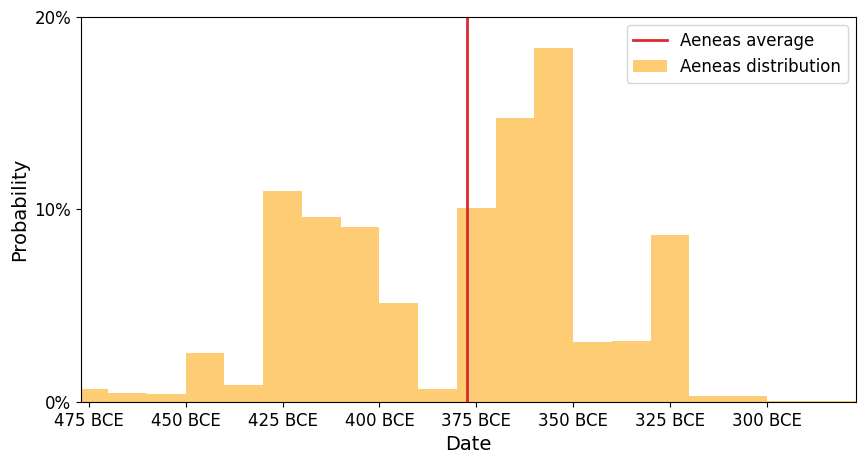

αρχείο 2: IG_II2_1807_Rotation1_300dpi_letters.txt\
aeneas output:\
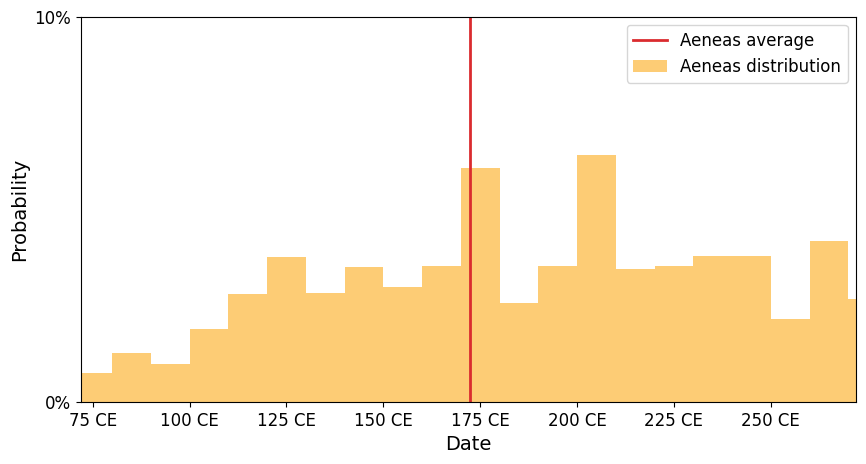

αρχείο 3: IG_II2_1801_Copy2_Rotation2_300dpi_letters.txt\
aeneas output:\
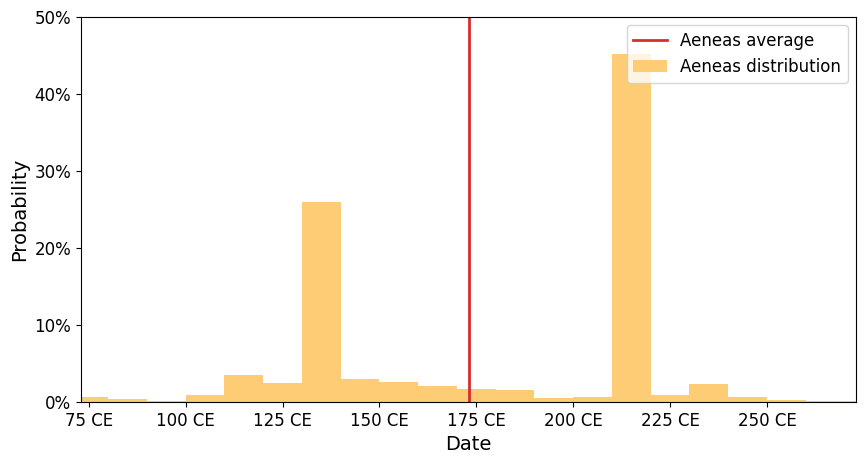

αρχείο 4: IG_II2_2010_Copy1_Rotation1_300dpi_letters.txt\
aeneas output: text too short

αρχείο 5: IG_II2_134_Rotation2_300dpi_letters.txt\
aeneas output:\
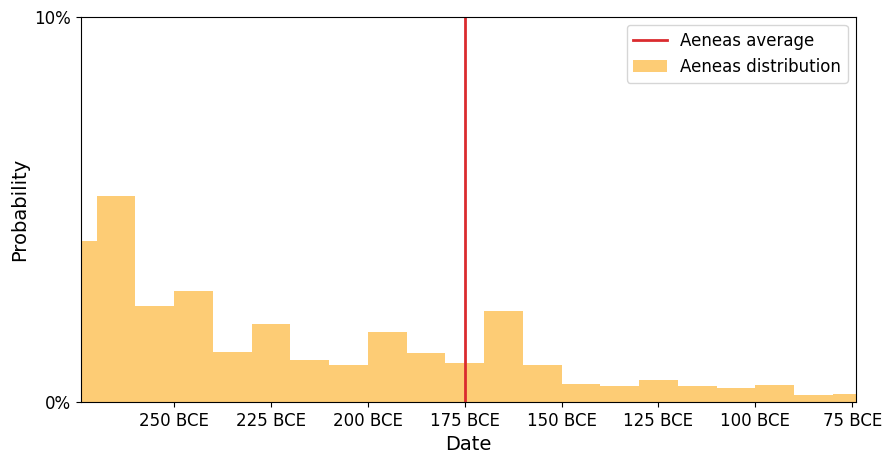

αρχείο 6: IG_II2_1794_Rotation1_300dpi_letters.txt\
aeneas output:\
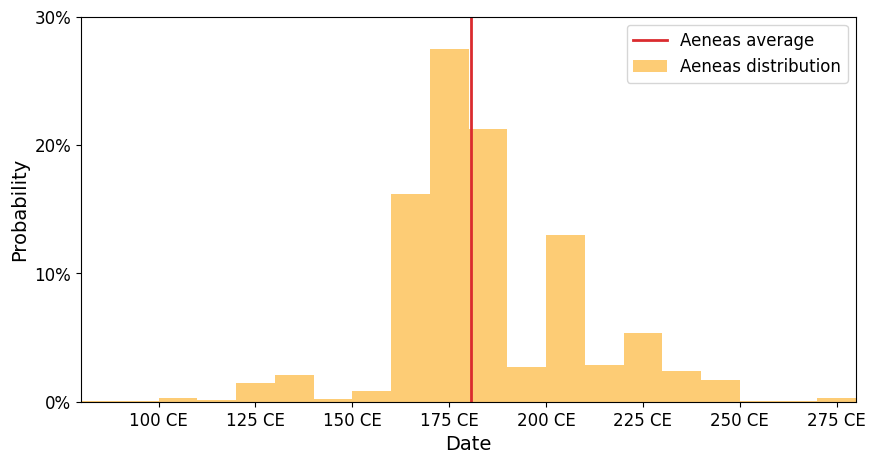

αρχείο 7: IG_II2_342_Rotation2_300dpi_letters.txt\
aeneas output:\
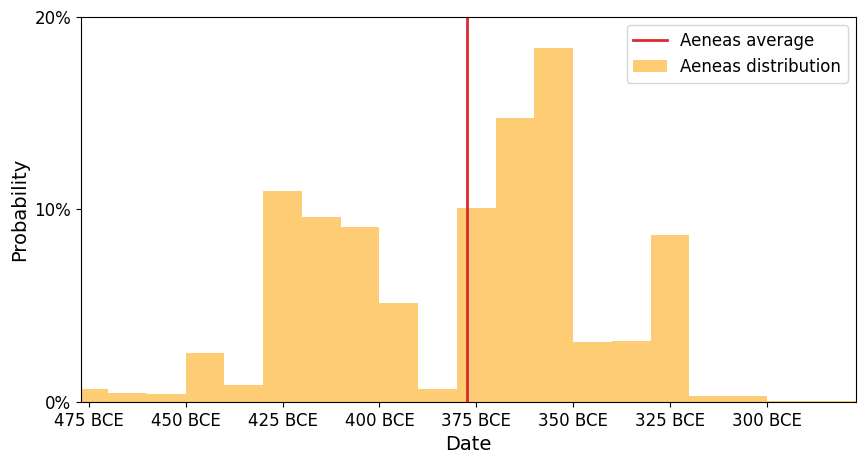

αρχείο 8: IG_II2_1946_Rotation1_300dpi_letters.txt\
aeneas output:\
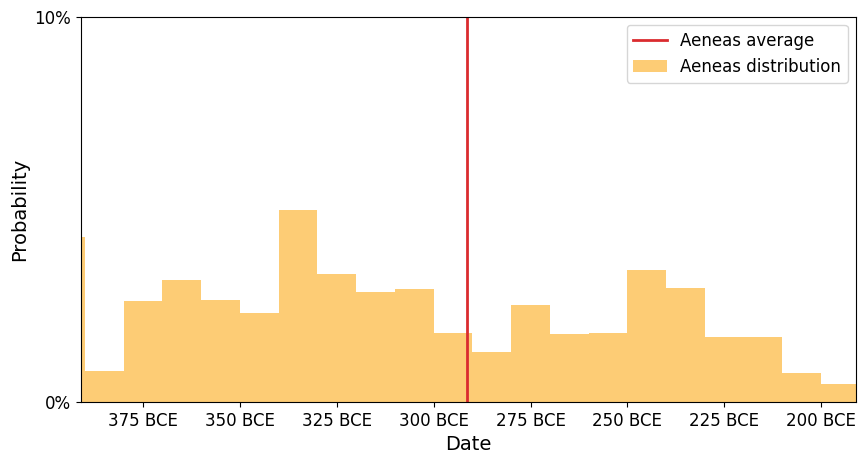


αρχείο 9: IAS33126_Merged_Rotation2_300dpi_letters.txt\
aeneas output:\
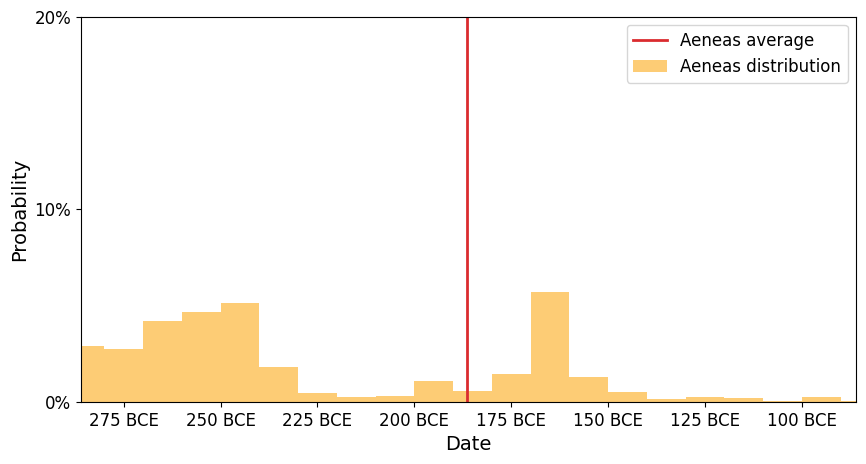

αρχείο 10: IG_II2_1693_Copy2_Rotation1_300dpi_letters.txt\
aeneas output:\
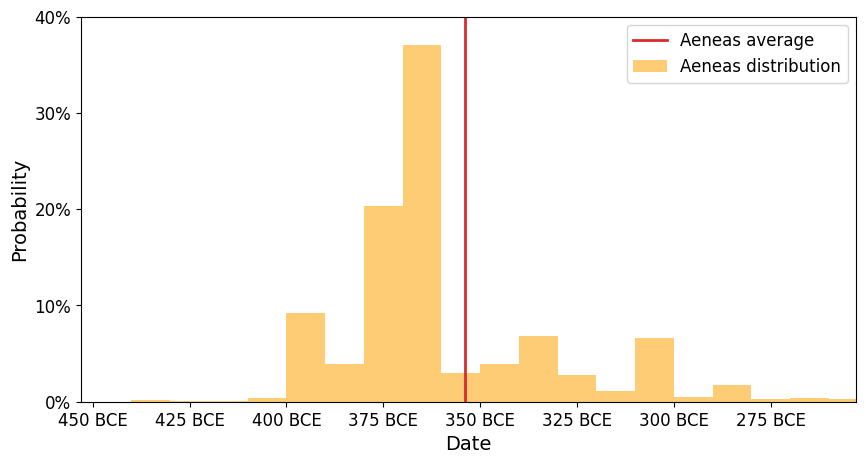

### Συγκριτική Χρονολόγηση Επιγραφών: Aeneas vs Gemini

| Αρ. | Aeneas (Πρόβλεψη) | Gemini (Πρόβλεψη) | Παρατηρήσεις |
| :--- | :--- | :--- | :--- |
| **1** | 377 π.Χ. | 1 – 200 μ.Χ. | Μεγάλη απόκλιση |
| **2** | 170 μ.Χ. | 101 – 300 μ.Χ. | Συμβατά αποτελέσματα |
| **3** | 174 μ.Χ. | 101 – 250 μ.Χ. | Συμβατά αποτελέσματα |
| **4** | N/A | 400 – 301 π.Χ. | Μηδενική πρόβλεψη (Aeneas) |
| **5** | 175 π.Χ. | 250 – 151 π.Χ. | Ικανοποιητική σύγκλιση |
| **6** | 180 μ.Χ. | 101 – 250 μ.Χ. | Συμβατά αποτελέσματα |
| **7** | 376 π.Χ. | 1 – 200 μ.Χ. | Μεγάλη απόκλιση |
| **8** | 290 π.Χ. | 200 – 101 π.Χ. | Μέτρια απόκλιση |
| **9** | 180 π.Χ. | 1 – 250 μ.Χ. | Ευρύ φάσμα αβεβαιότητας |
| **10** | 355 π.Χ. | 450 – 301 π.Χ. | Συμβατά αποτελέσματα |

Τα γενικά AI (όπως το Gemini) έχουν γενικές γνώσεις για τα πάντα, αλλά δεν είναι εξειδικευμένα όπως το Aeneas που είναι φτιαγμένο μόνο για αυτή τη δουλειά.

Το Aeneas είναι καλύτερο γιατί διάβασε χιλιάδες επιγραφές για να εκπαιδευτεί, οπότε καταλαβαίνει καλύτερα το στυλ τους. Το Gemini είναι χρήσιμο για να σου δώσει το γενικό πλαίσιο (π.χ. "τι γινόταν εκείνη την εποχή"), αλλά δεν μπορείς να το εμπιστευτείς 100% για να βρει την ακριβή ημερομηνία μιας πέτρας.

Όπως φαίνεται και από το πινακάκι σε διάφορες περπτώσεις έχουν σημαντική απόκλιση, οπότε σίγουρα τα γενικά ai κάνουν λάθη. Μπορούν ίσως να χρησιμοποιηθούν από ειδικούς για να τους στρέψουν προς τη σωστή κατεύθηνση όμως η τελική απόφαση παίρνεται από άνθρωπο.


Παρατηρώντας τα αποτελέσματα των 10 επιγραφών, γίνεται σαφές ότι τα μοντέλα AI μοιράζονται ένα θεμελιώδες πρόβλημα: την αδυναμία τους να διαχειριστούν δεδομένα χαμηλής ποιότητας. Ουσιαστικά υπάρχει Garbage In, Garbage Out.


## Μέρος Β — Ανάλυση Εικόνων

Imports για μέρος Β

In [ ]:
import cv2
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import shutil
from tqdm.notebook import tqdm
import torch
from PIL import Image
from transformers import ViTImageProcessor, ViTModel
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from scipy.spatial import ConvexHull
import umap
from sklearn.metrics import pairwise_distances
from sklearn.metrics import silhouette_score
import google.generativeai as genai


/usr/local/lib/python3.12/dist-packages/google/colab/_import_hooks/_hook_injector.py:55: FutureWarning: 

All support for the `google.generativeai` package has ended. It will no longer be receiving 
updates or bug fixes. Please switch to the `google.genai` package as soon as possible.
See README for more details:

https://github.com/google-gemini/deprecated-generative-ai-python/blob/main/README.md

  loader.exec_module(module)


**Β1.** Σε αυτό το μέρος καλείστε να πραγματοποιήσετε Αναγνώριση Κειμένου (Text Recognition) από τις εικόνες του dataset. Πρώτα, παρέχετε δειγματικές απεικονίσεις των βημάτων προεπεξεργασίας εικόνων σας. Στόχος: καθαρισμός εικόνων, μείωση θορύβου.

Πρέπει να δείξετε:
- i. Τις αρχικές εικόνες/δείγματα
- ii. Τα βήματα προεπεξεργασίας στα ίδια δείγματα
- iii. Τις καθαρισμένες εικόνες


### Προεπεξεργασία Εικόνων & Μείωση Θορύβου

Στο παρακάτω κελί εκτελούμε την απαραίτητη προεπεξεργασία για τον καθαρισμό των εικόνων και τη μείωση του θορύβου. Στα δεδομένα μας (squeezes), η κρίσιμη πληροφορία βρίσκεται στις σκιές των γραμμάτων, ενώ η υφή του χαρτιού αποτελεί ανεπιθύμητο θόρυβο.

Ο λόγος που επιλέξαμε τη συγκεκριμένη αλληλουχία μεθόδων είναι ο εξής:

* **Grayscale (Ασπρόμαυρο):** Το χρώμα δεν προσφέρει ουσιαστική πληροφορία για τα ανάγλυφα· μας ενδιαφέρει αποκλειστικά η αντίθεση φωτός-σκιάς.
* **CLAHE (Τοπική Ενίσχυση Αντίθεσης):** Αναδεικνύει τις σκιές των γραμμάτων βελτιώνοντας την αντίθεση τοπικά, εξισορροπώντας έτσι τον άνισο φωτισμό της φωτογραφίας.
* **Bilateral Filter (Διμερές Φίλτρο):** Εξαλείφει τους πόρους και την υφή του χαρτιού, διατηρώντας ταυτόχρονα καθαρές και ανέπαφες τις ακμές των γραμμάτων.
* **Unsharp Masking (Όξυνση):** Τονίζει στο μέγιστο το ανάγλυφο αποτέλεσμα, κάνοντας τα γράμματα πιο «αιχμηρά» και ευδιάκριτα.

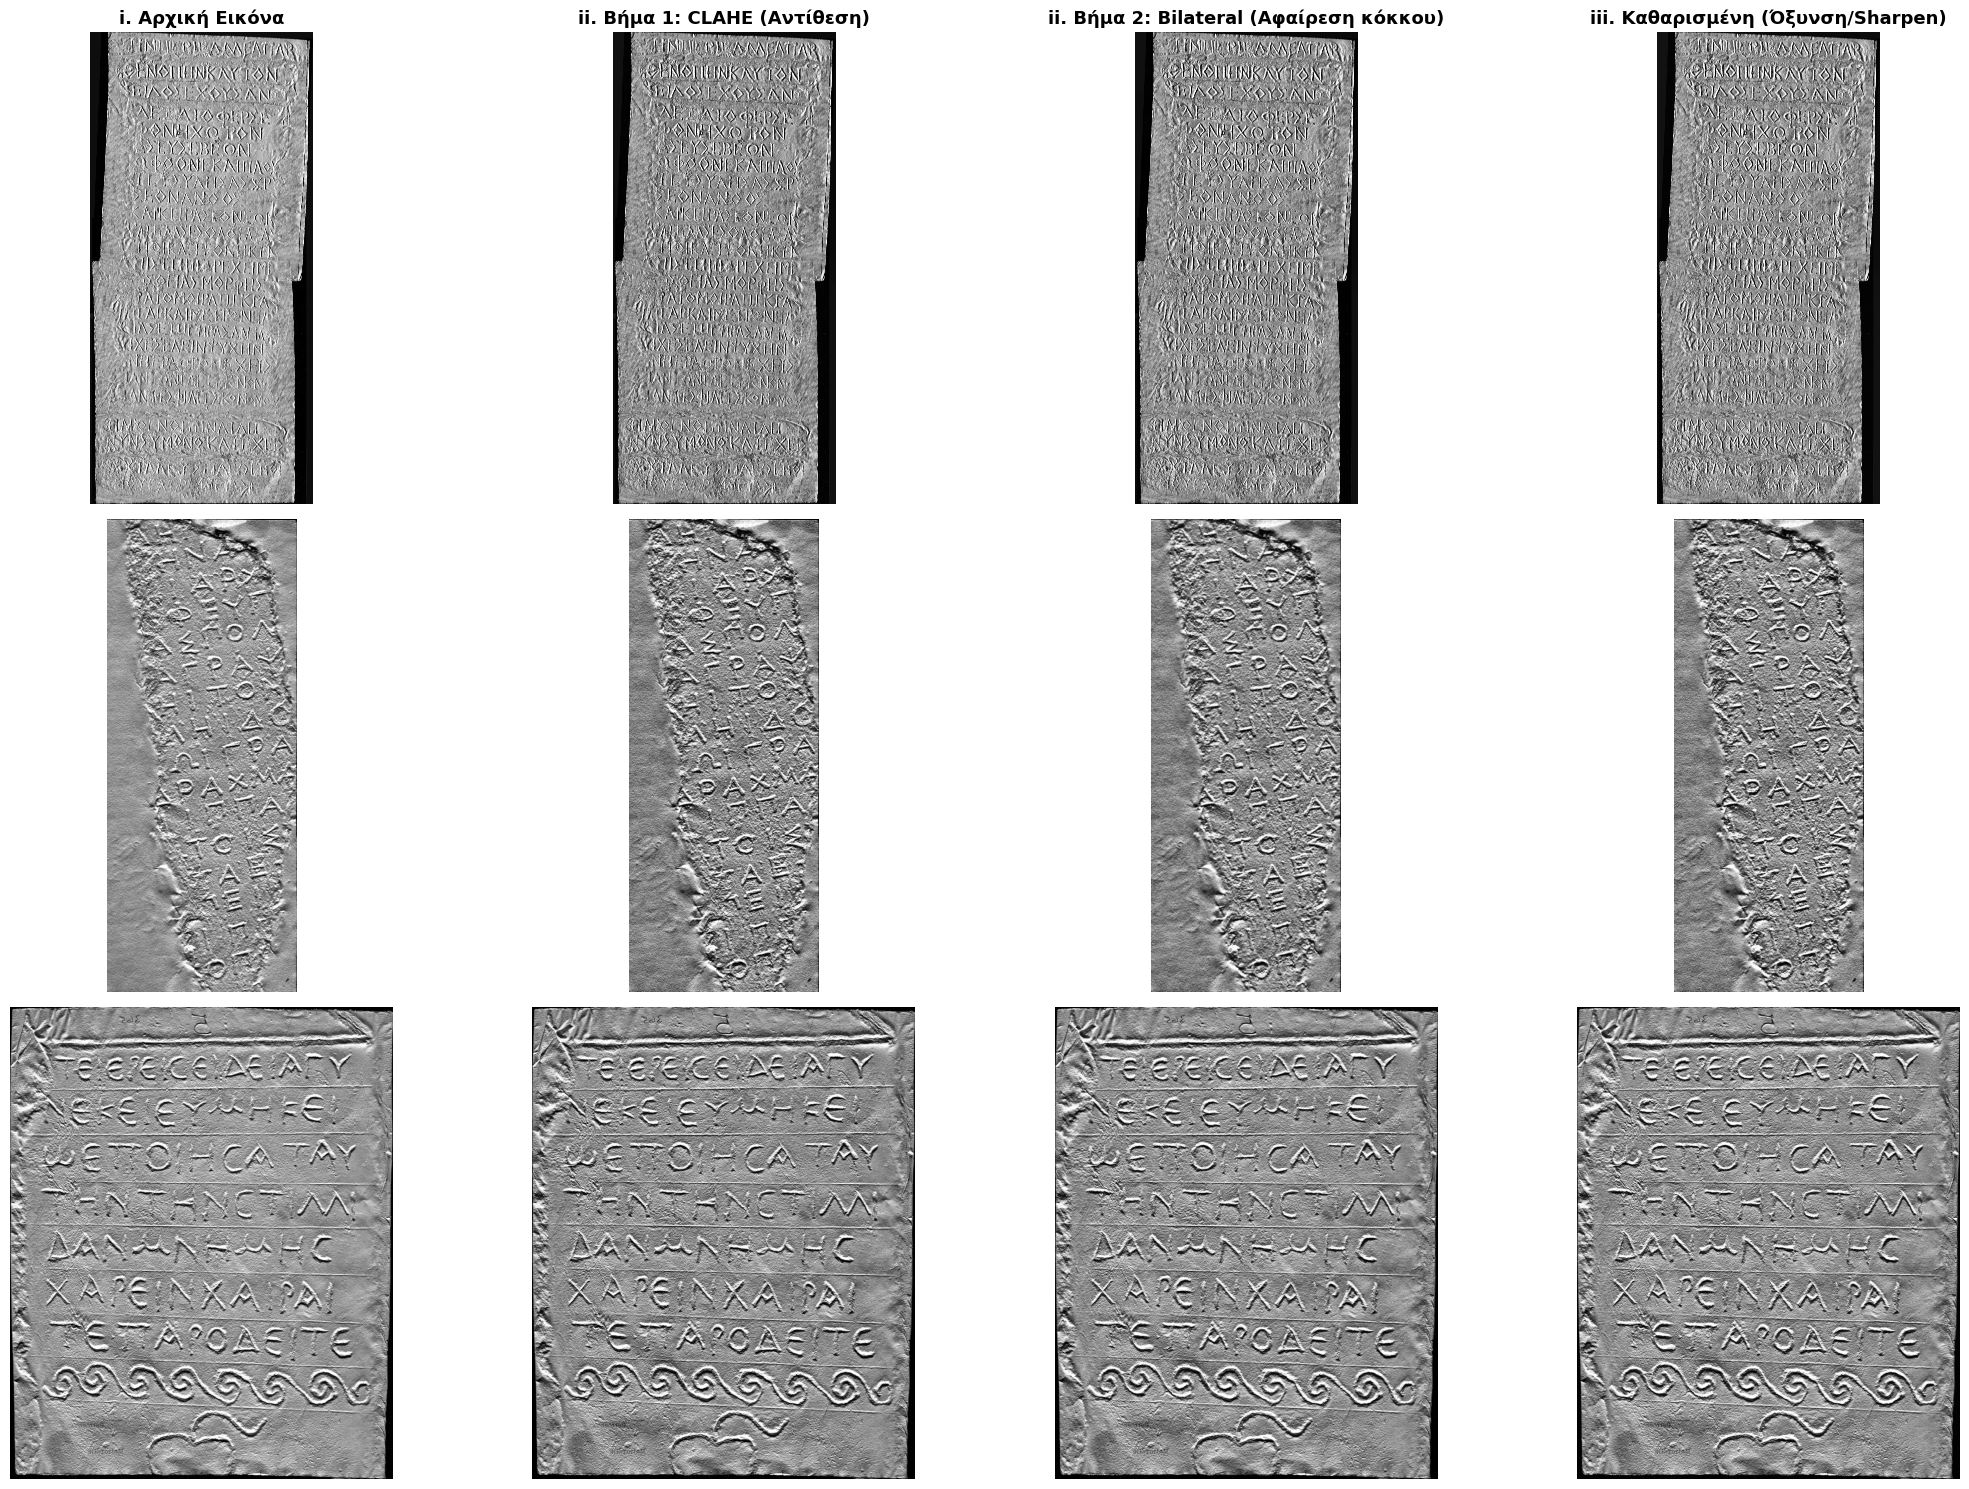

In [ ]:
# TODO: Προεπεξεργασία εικόνων — δείξτε i) originals, ii) preprocessing steps, iii) cleaned


IMAGE_DIR = '/content/Images1/'

sample_images = glob.glob(os.path.join(IMAGE_DIR, '*.png'))[:3]


def preprocess_squeeze(img_path):

    original = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

    if original is None:
        return None, None, None, None

    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    enhanced = clahe.apply(original)
     # d=9: Διάμετρος γειτονιάς, sigmaColor/Space=75: Πόσο μακριά μιξάρονται τα pixels
    bilateral = cv2.bilateralFilter(enhanced, d=9, sigmaColor=75, sigmaSpace=75)
    gaussian = cv2.GaussianBlur(bilateral, (0, 0), 2.0)
    cleaned = cv2.addWeighted(bilateral, 1.5, gaussian, -0.5, 0)

    return original, enhanced, bilateral, cleaned

if not sample_images:
    print("Δεν βρέθηκαν εικόνες! Έλεγξε τη διαδρομή.")
else:
    fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(22, 15))
    titles = [
      'i. Αρχική Εικόνα',
      'ii. Βήμα 1: CLAHE (Αντίθεση)',
      'ii. Βήμα 2: Bilateral (Αφαίρεση κόκκου)',
      'iii. Καθαρισμένη (Όξυνση/Sharpen)'
    ]

    for i, path in enumerate(sample_images):
      orig, enh, bilat, clean = preprocess_squeeze(path)
      images = [orig, enh, bilat, clean]

      for j in range(4):
          ax = axes[i, j]
          ax.imshow(images[j], cmap='gray')
          ax.axis('off')

          if i == 0:
            ax.set_title(titles[j], fontsize=13, fontweight='bold')

    plt.tight_layout()
    plt.show()

Φτιάξαμε πρώτα μια συνάρτηση που επεξεργάζεται αρχικά μόνο 3 από τις εικόνες του dataset ώστε να κάνουμε δοκιμές, μέχρι να καταλήξουμε στην τελική επεξεργασία που θα εφαρμοστεί σε όλο το dataset. Παρακάτω εφαρμόζουμε την προεπεξεργασία στα Images1, Images4.

In [ ]:

folders_to_process = ['Images1', 'Images4']

for folder in folders_to_process:

    print(f"ΕΝΑΡΞΗ ΕΠΕΞΕΡΓΑΣΙΑΣ ΓΙΑ: {folder}")

    COLAB_SOURCE_DIR = f'/content/{folder}/'
    COLAB_CLEANED_DIR = f'/content/Cleaned_{folder}/'

    # Δημιουργούμε τον φάκελο στο Colab για να αποθηκεύσουμε τα καθαρά αρχεία
    os.makedirs(COLAB_CLEANED_DIR, exist_ok=True)

    all_images = glob.glob(os.path.join(COLAB_SOURCE_DIR, '*.png'))

    print(f"=== Βήμα 1: Επεξεργασία {len(all_images)} εικόνων τοπικά στο Colab ===")

    for img_path in tqdm(all_images, desc=f"Επεξεργασία {folder}"):

        filename = os.path.basename(img_path)
        save_path = os.path.join(COLAB_CLEANED_DIR, filename)

        orig, enh, bilat, cleaned = preprocess_squeeze(img_path)

        if cleaned is not None:
            cv2.imwrite(save_path, cleaned)


ΕΝΑΡΞΗ ΕΠΕΞΕΡΓΑΣΙΑΣ ΓΙΑ: Images1
=== Βήμα 1: Επεξεργασία 74 εικόνων τοπικά στο Colab ===


Επεξεργασία Images1:   0%|          | 0/74 [00:00<?, ?it/s]

ΕΝΑΡΞΗ ΕΠΕΞΕΡΓΑΣΙΑΣ ΓΙΑ: Images4
=== Βήμα 1: Επεξεργασία 116 εικόνων τοπικά στο Colab ===


Επεξεργασία Images4:   0%|          | 0/116 [00:00<?, ?it/s]

Παρακάτω είναι κώδικας για την αποθήκευση των καθαρών εικόνων στο Drive

In [ ]:
DRIVE_DEST_DIR = f'/content/drive/MyDrive/GREEK_SQUEEZES/Cleaned_{folder}/'

print(f"\n=== Βήμα 2: Αντιγραφή των καθαρών εικόνων ({folder}) στο Google Drive ===")
print("Αυτό μπορεί να πάρει 1-2 λεπτά. Παρακαλώ περιμένετε...")

if os.path.exists(DRIVE_DEST_DIR):
    shutil.rmtree(DRIVE_DEST_DIR)

shutil.copytree(COLAB_CLEANED_DIR, DRIVE_DEST_DIR)

print(f"=== Ολοκληρώθηκε ο {folder}! ===")
print(f"Οι καθαρές εικόνες βρίσκονται πλέον μόνιμα στο: {DRIVE_DEST_DIR}")

**Β2.** Χρησιμοποιήστε embeddings από ένα οπτικό μοντέλο για να ομαδοποιήσετε τις εικόνες βάσει οπτικής ομοιότητας.

**Οδηγίες:**
- Εξαγάγετε embeddings από ένα οπτικό μοντέλο (π.χ. ViT).
- Χρησιμοποιήστε **PCA**, **t-SNE** ή/και **UMAP** για ομαδοποίηση και απεικόνιση.
- Εκτυπώστε εικόνες κοντά στα κεντροειδή κάθε cluster (π.χ. 3 εικόνες ανά κεντροειδές).
- Ονομάστε τα θέματα (topics) 3 clusters — χρησιμοποιήστε τα filenames για να ελέγξετε αν ανήκουν στην ίδια εποχή.
- Χρησιμοποιήστε ένα LLM για να αυτοματοποιήσετε την ονοματοδοσία θεμάτων.
- Αναλύστε: Βρίσκονται ζεύγη εικόνων στο ίδιο cluster; Εικόνες από τον ίδιο τόπο/αρχείο;




Σε αυτό το κελί υλοποιούμε ομαδοποιούμε (clustering) τις καθαρισμένες είκονες των επιγραφών, με χρήση του μοντέλου ViT που βασίζεται στην οπτική τους ομοιότητα.

* **Εξαγωγή Embeddings με Vision Transformer (ViT):** Χρησιμοποιούμε το προ-εκπαιδευμένο μοντέλο (ViT). Το μοντέλο αυτό «διαβάζει» την εικόνα και την κωδικοποιεί σε ένα διάνυσμα αριθμών (embedding), αποτυπώνοντας τα βαθύτερα οπτικά χαρακτηριστικά της (όπως πυκνότητα γραμμάτων, φθορές λίθου ή στυλ χάραξης).
* **Μείωση Διαστάσεων με PCA (στα 50):** Τα διανύσματα του ViT έχουν εκατοντάδες διαστάσεις. Το PCA συμπιέζει την πληροφορία στις 50 πιο κρίσιμες διαστάσεις, αφαιρώντας τον θόρυβο και κρατώντας την ουσία.
* **Ομαδοποίηση με K-Means:** Εφαρμόζουμε τον αλγόριθμο K-Means στα δεδομένα των 50 διαστάσεων για να εντοπίσουμε μαθηματικές και οπτικές  ομοιότητες και να χωρίσουμε τις εικόνες σε 3 διακριτά clusters (όπως ζητά η εκφώνηση).
* **Δισδιάστατη Απεικόνιση με UMAP & Convex Hull:** Επειδή ο ανθρώπινος εγκέφαλος δεν μπορεί να δει σε 50 διαστάσεις, το UMAP αναλαμβάνει να αναπαραστήσει τα δεδομένα σε 2 διαστάσεις (X, Y), φροντίζοντας οι οπτικά παρόμοιες εικόνες να παραμείνουν κοντά η μία στην άλλη. Τέλος, χρησιμοποιούμε τα πολύγωνα (Convex Hulls) για να κυκλώσουμε οπτικά τις ομάδες στο γράφημα, κάνοντας τα clusters απόλυτα ξεκάθαρα. Προτιμήσαμε το UMAP απο το t-SNE επειδή είναι πιο γρήγορο, διατηρεί καλύτερα την καθολική δομή των δεδομένων και αποτιπώνει με μεγαλύτερη ακρίβεια τις αποστάσεις μεταξύ των clusters.

Χρησιμοποιείται συσκευή: cpu


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Βρέθηκαν 74 εικόνες στον φάκελο 1.
Βρέθηκαν 116 εικόνες στον φάκελο 4.
ΣΥΝΟΛΟ: Βρέθηκαν 190 εικόνες για εξαγωγή embeddings.


Extracting ViT Embeddings:   0%|          | 0/190 [00:00<?, ?it/s]


Εφαρμογή PCA (Μείωση σε 50 διαστάσεις)

Εφαρμογή K-Means για 3 clusters
Εφαρμογή UMAP για απεικόνιση 2D


/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


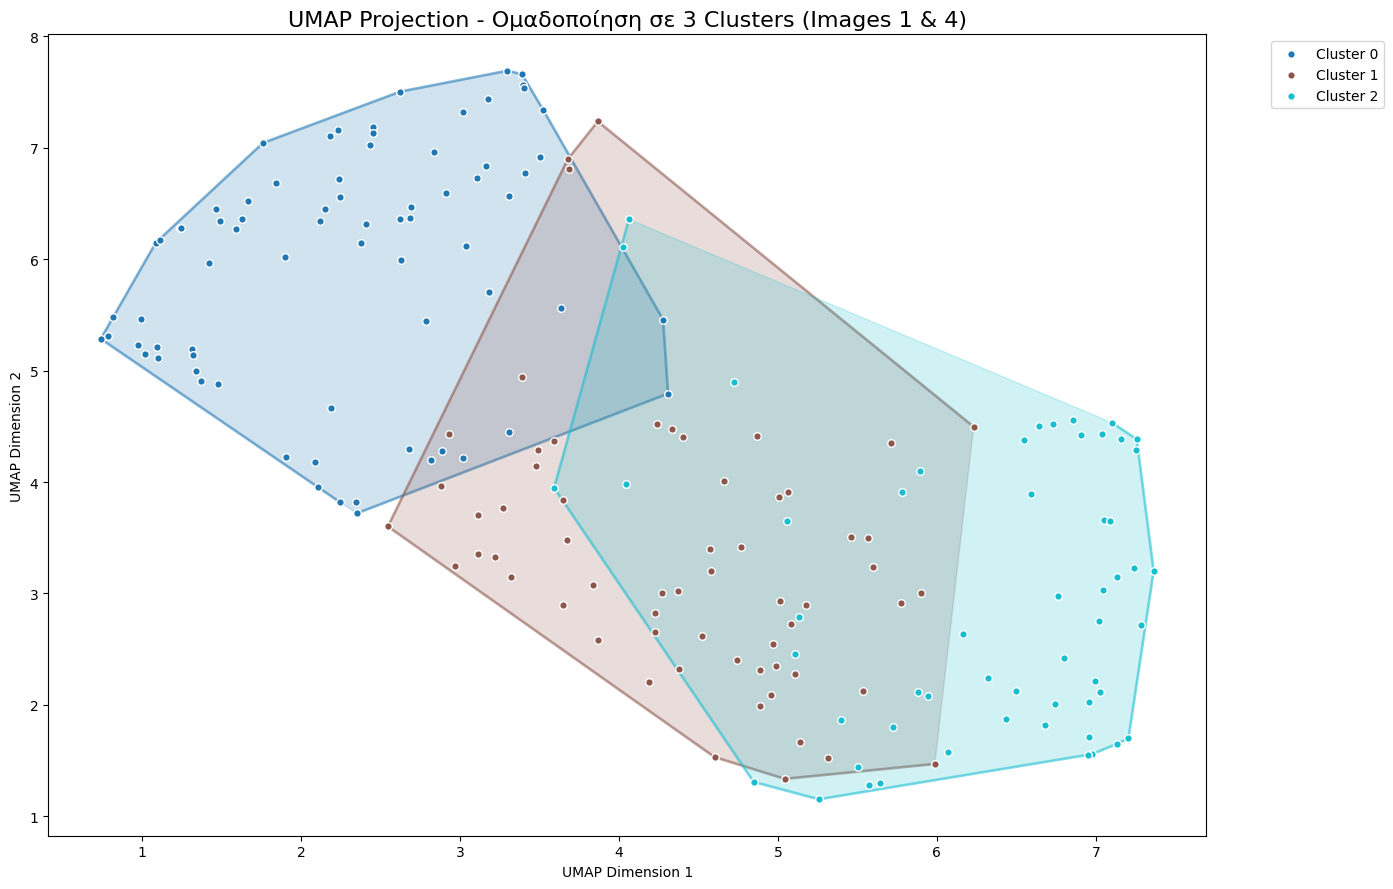

In [ ]:
#Ομαδοποίηση εικόνων μέσω embeddings (ViT), PCA, UMAP, LLM topic naming

Image.MAX_IMAGE_PIXELS = None

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Χρησιμοποιείται συσκευή: {device}")

processor = ViTImageProcessor.from_pretrained('google/vit-base-patch16-224-in21k')
model = ViTModel.from_pretrained('google/vit-base-patch16-224-in21k').to(device)
model.eval()

CLEANED_DIR_1 = '/content/drive/MyDrive/GREEK_SQUEEZES/Cleaned_Images1/'
CLEANED_DIR_4 = '/content/drive/MyDrive/GREEK_SQUEEZES/Cleaned_Images4/'

image_paths_1 = glob.glob(os.path.join(CLEANED_DIR_1, '*.png'))
image_paths_4 = glob.glob(os.path.join(CLEANED_DIR_4, '*.png'))
image_paths = image_paths_1 + image_paths_4

print(f"Βρέθηκαν {len(image_paths_1)} εικόνες στον φάκελο 1.")
print(f"Βρέθηκαν {len(image_paths_4)} εικόνες στον φάκελο 4.")
print(f"ΣΥΝΟΛΟ: Βρέθηκαν {len(image_paths)} εικόνες για εξαγωγή embeddings.")

embeddings = []
valid_paths = []

with torch.no_grad():
    for img_path in tqdm(image_paths, desc="Extracting ViT Embeddings"):
        try:
            image = Image.open(img_path).convert('RGB')
            inputs = processor(images=image, return_tensors="pt").to(device)
            outputs = model(**inputs)

            img_embedding = outputs.last_hidden_state[:, 0, :].cpu().numpy().squeeze()
            embeddings.append(img_embedding)
            valid_paths.append(img_path)
        except Exception as e:
            pass

embeddings = np.array(embeddings)

print("\nΕφαρμογή PCA (Μείωση σε 50 διαστάσεις)")
pca = PCA(n_components=50, random_state=42)
embeddings_pca = pca.fit_transform(embeddings)

NUM_CLUSTERS = 3
print(f"\nΕφαρμογή K-Means για {NUM_CLUSTERS} clusters")

kmeans_3 = KMeans(n_clusters=NUM_CLUSTERS, random_state=42, n_init='auto')
cluster_labels_3 = kmeans_3.fit_predict(embeddings_pca)

print("Εφαρμογή UMAP για απεικόνιση 2D")
reducer = umap.UMAP(n_components=2, random_state=42)
embeddings_umap = reducer.fit_transform(embeddings_pca)

plt.figure(figsize=(14, 9))
colors = plt.cm.tab10(np.linspace(0, 1, NUM_CLUSTERS))

for i in range(NUM_CLUSTERS):
    points = embeddings_umap[cluster_labels_3 == i]
    plt.scatter(points[:, 0], points[:, 1], color=colors[i], label=f'Cluster {i}', s=30, edgecolors='w', zorder=2)

    if len(points) >= 3:
        hull = ConvexHull(points)
        plt.fill(points[hull.vertices, 0], points[hull.vertices, 1], color=colors[i], alpha=0.2, zorder=1)
        plt.plot(points[hull.vertices, 0], points[hull.vertices, 1], color=colors[i], lw=2, alpha=0.5, zorder=1)

plt.title(f'UMAP Projection - Ομαδοποίηση σε {NUM_CLUSTERS} Clusters (Images 1 & 4)', fontsize=16)
plt.xlabel('UMAP Dimension 1')
plt.ylabel('UMAP Dimension 2')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

Παρακάτω εκτελώντας πολλές φορές K-means για διαφορετικά Κ και συγκρίνοντας τα Silhouette scores αποδεικνύουμε ότι ο βέλτιστος αριθμός clusters είναι 2. Εμείς όμως χρησιμοποιήσαμε 3 διότι έτσι μας έλεγε η εκφώνηση.


Αναζήτηση του πραγματικά βέλτιστου K (από 2 έως 10)...
Το μαθηματικά βέλτιστο K βρέθηκε: 2 Clusters (Silhouette Score: 0.1480)


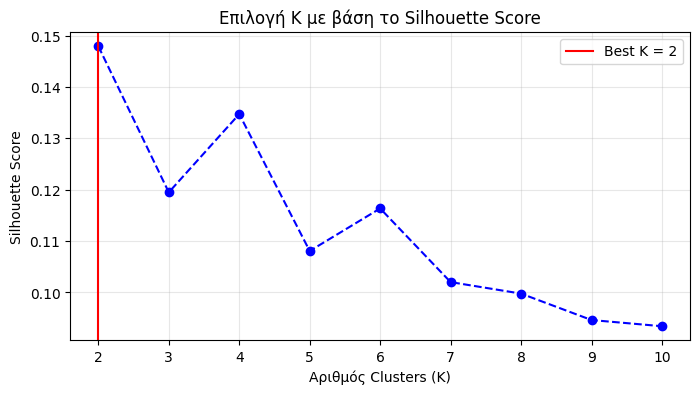

In [ ]:
print("\nΑναζήτηση του πραγματικά βέλτιστου K (από 2 έως 10)...")
best_k = 2
best_score = -1
silhouette_scores = []

k_range = range(2, 11)
for k in k_range:
    kmeans_temp = KMeans(n_clusters=k, random_state=42, n_init='auto')
    labels_temp = kmeans_temp.fit_predict(embeddings_pca)
    score = silhouette_score(embeddings_pca, labels_temp)
    silhouette_scores.append(score)

    if score > best_score:
        best_score = score
        best_k = k

print(f"Το μαθηματικά βέλτιστο K βρέθηκε: {best_k} Clusters (Silhouette Score: {best_score:.4f})")

# Σχεδιασμός Γραφήματος Silhouette
plt.figure(figsize=(8, 4))
plt.plot(k_range, silhouette_scores, marker='o', linestyle='--', color='b')
plt.axvline(x=best_k, color='r', linestyle='-', label=f'Best K = {best_k}')
plt.title('Επιλογή Κ με βάση το Silhouette Score')
plt.xlabel('Αριθμός Clusters (K)')
plt.ylabel('Silhouette Score')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Στο παρακάτω κελί:

* Υπολογίζουμε την απόσταση κάθε εικόνας από το κέντρο της ομάδας της και τυπώνουμε τις 3 πιο κοντινές. Αυτό μας επιτρέπει να κατανοήσουμε με μια ματιά το οπτικό κριτήριο ομαδοποίησης του ViT για κάθε cluster. To ViT δεν κατανοεί τα αρχαία Ελλήνικα, οπότε κατατάσσει με βάση μορφολογικά και δομικά μοτίβα.
* **Παρατηρήσεις ομαδοποίησης:**  Φαίνεται επιγραφές παρόμοιου σχήματος να ταξινομούνται μαζί. Οι φωτογραφίες που απεικονίζουν την ίδια επιγραφή απο διαφορετική γωνία, κατα πληοψηφία βρίσκονται στο ίδιο cluster. Προτάσεις για ονοματοδοσία clusters με βάση την προέλευση των επιγραφών:
  
  cluster 0 : Επιγραφές Αττικής (Κλασικής, Ελληνιστικής, Ρωμαϊκής εποχής )

  cluster 1 : Επιγραφές Αττικής και Ευρύτερης Μεσογείου (κυρίως ορθογώνιες παραλληλόγραμμες)
  
  cluster 2 : Επιγραφές Αττικής και Ευρύτερης Μεσογείου (κυρίως στρογγυλές σε μεγένθυνση)

  
* **Προετοιμασία για το LLM:** Αποθηκεύουμε τα ονόματα των αρχείων (`cluster_filenames`) κάθε ομάδας. Αυτά θα τροφοδοτηθούν στη συνέχεια σε ένα LLM, το οποίο θα ελέγξει τα metadata (π.χ. εποχή, τόπος) για να αναλάβει την αυτοματοποιημένη ονοματοδοσία των θεμάτων.

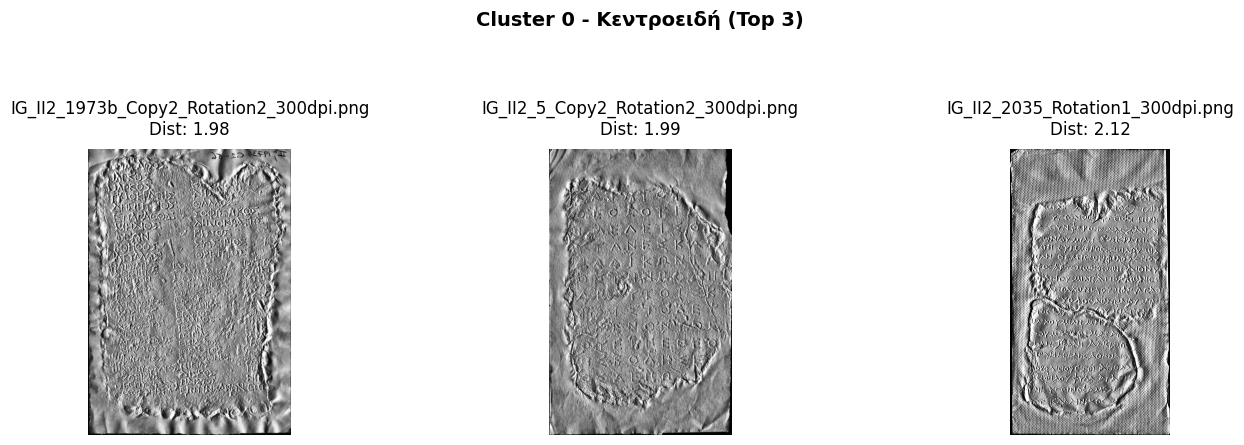

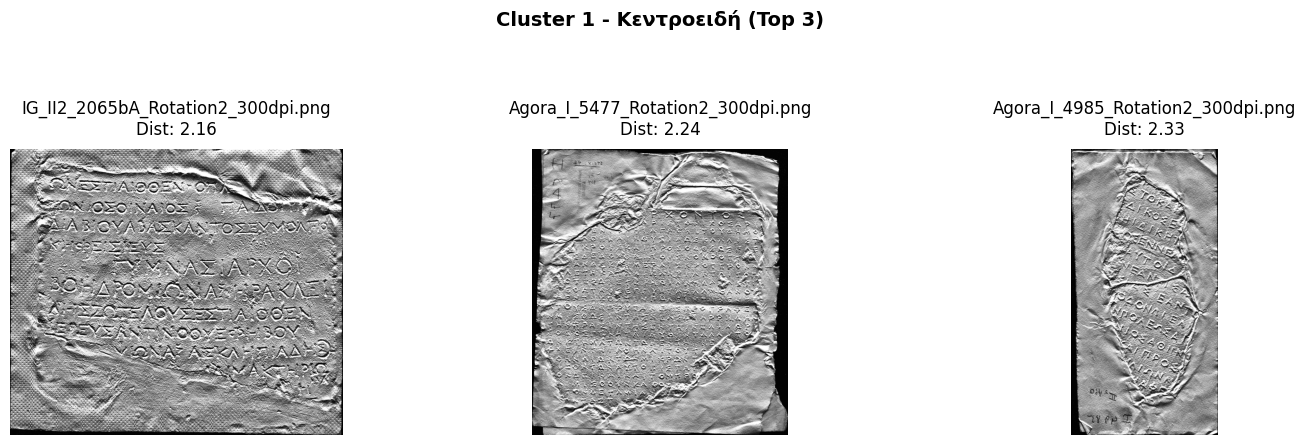

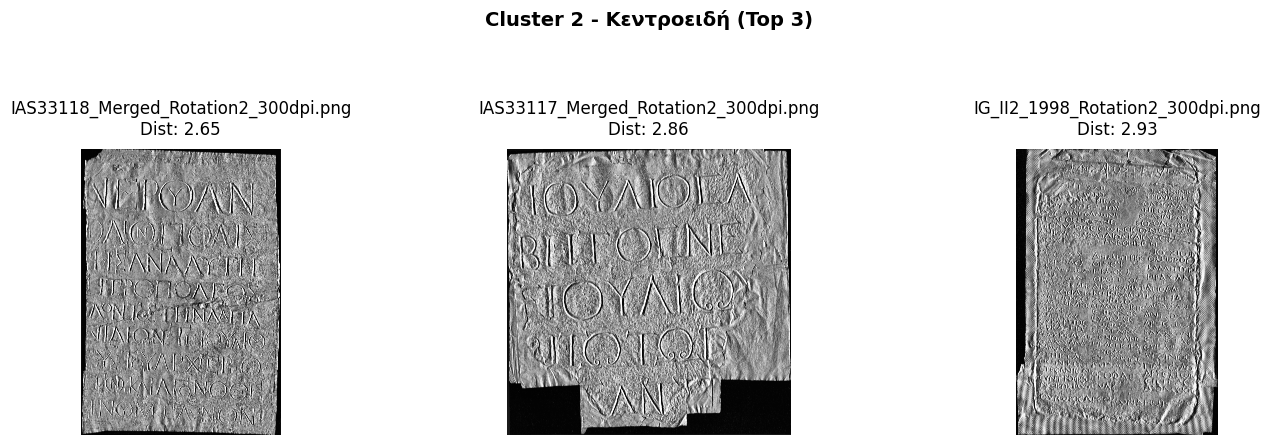

In [ ]:

cluster_filenames = {i: [] for i in range(NUM_CLUSTERS)}

for cluster_id in range(NUM_CLUSTERS):
    indices = np.where(cluster_labels_3 == cluster_id)[0]

    if len(indices) == 0:
        print(f"Το Cluster {cluster_id} δεν έχει καμία εικόνα!")
        continue

    for idx in indices:
        cluster_filenames[cluster_id].append(os.path.basename(valid_paths[idx]))

    cluster_pts = embeddings_pca[indices]
    centroid = kmeans_3.cluster_centers_[cluster_id].reshape(1, -1)
    distances = pairwise_distances(cluster_pts, centroid).squeeze()

    if distances.ndim == 0:
        distances = np.array([distances])

    num_to_show = min(3, len(distances))
    closest_local_indices = np.argsort(distances)[:num_to_show]
    closest_global_indices = indices[closest_local_indices]

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    fig.suptitle(f'Cluster {cluster_id} - Κεντροειδή (Top {num_to_show})',
                 fontsize=14, fontweight='bold', y=1.1)

    for ax in axes:
        ax.axis('off')

    for i, global_idx in enumerate(closest_global_indices):
        img_path = valid_paths[global_idx]
        filename = os.path.basename(img_path)
        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

        axes[i].imshow(img, cmap='gray')
        axes[i].set_title(f"{filename}\nDist: {distances[closest_local_indices[i]]:.2f}", pad=10)
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()

Παρακάτω χρησιμοποιούμε το Gemini για να αυτοματοποιήσουμε την ονοματοδοσία θεμάτων. Του δείχνουμε 30 εικόνες απο κάθε cluster. Του λέμε να μας απαντήσει για κάθε cluster:

* **Ονομασία Θέματος:** Έναν σύντομο, περιγραφικό τίτλο για την ομάδα.
* **Τόπος & Εποχή:** Έλεγχο των προθεμάτων (π.χ. IG_II2) για κοινή ιστορική ή γεωγραφική προέλευση.
* **Ζεύγη Εικόνων:** Έλεγχο αν οι διαφορετικές λήψεις της ίδιας επιγραφής (π.χ. `_Rotation1`, `_Rotation2`) παρέμειναν μαζί ή χωρίστηκαν.
* **Τελικό Συμπέρασμα:** Αξιολόγηση αν το μοντέλο ομαδοποίησε τελικά με βάση το ιστορικό υπόβαθρο (προέλευση) ή καθαρά οπτικά/τεχνικά χαρακτηριστικά (φωτισμός).

In [ ]:

GOOGLE_API_KEY = ""
if not GOOGLE_API_KEY:
    raise ValueError("Google API Key is missing!")
genai.configure(api_key=GOOGLE_API_KEY)

clusters_to_analyze = [0, 1, 2]

llm = genai.GenerativeModel('gemini-2.5-flash')

for c_id in clusters_to_analyze:
    sample_files = sorted(cluster_filenames[c_id][:30])
    filenames_str = "\n".join(sample_files)

    prompt = f"""
    Είσαι ένας ειδικός αναλυτής δεδομένων και επιγραφικής. Έχουμε ένα μοντέλο clustering (ViT) που ομαδοποίησε εικόνες από αρχαίες επιγραφές αποκλειστικά βάσει οπτικών χαρακτηριστικών.

    Εδώ είναι η λίστα με τα ονόματα των αρχείων που ταξινομήθηκαν στο Cluster {c_id}:
    {filenames_str}

    Ως background, λάβε υπόψη τα εξής για τα μεταδεδομένα (filenames):
    - Προθέματα: Το 'IG_II2' αφορά επιγραφές της Αττικής (συχνά Κλασικής/Ελληνιστικής/Ρωμαϊκής εποχής). Το 'Agora_I' αφορά την Αθηναϊκή Αγορά. Το 'IAS' είναι μια ευρύτερη συλλογή που καλύπτει όλη τη Μεσόγειο και διάφορες εποχές.
    - Καταλήξεις: Τα '_Rotation1', '_Rotation2', '_a', '_b' υποδηλώνουν διαφορετικές λήψεις φωτισμού ή όψεις της ίδιας επιγραφής (ζεύγη).

    ΑΠΑΓΟΡΕΥΕΤΑΙ να γράψεις θεωρία για το πώς λειτουργεί το ViT. Μελέτησε τα filenames που σου έδωσα παραπάνω και απάντησε ΑΥΣΤΗΡΑ με την εξής μορφή, καλύπτοντας τα ζητούμενα της άσκησής μας:

    **1. Προτεινόμενο Θέμα / Ονομασία Cluster:** (Δώσε έναν σύντομο τίτλο βάσει των κυρίαρχων μοτίβων στα filenames)

    **2. Ανάλυση Τόπου / Αρχείου / Εποχής:** (Βρίσκονται εικόνες από τον ίδιο τόπο/αρχείο στο ίδιο cluster; Τι παρατηρείς από τα προθέματα IG_II2, Agora, IAS; Μπορούμε να πούμε ότι ανήκουν στην ίδια εποχή ή γεωγραφική περιοχή βάσει αυτών;)

    **3. Ανάλυση στα Ζεύγη Εικόνων:** (Βρίσκονται ζεύγη εικόνων -π.χ. η ίδια επιγραφή σε Rotation1 και Rotation2- μέσα σε αυτό το cluster; Ή το μοντέλο τα χώρισε; Τι κυριαρχεί;)

    **4. Συμπεράσματα Ομαδοποίησης:** (Συνοπτικά: Το μοντέλο ομαδοποίησε βάσει της προέλευσης/εποχής της επιγραφής ή κυρίως βάσει των οπτικών χαρακτηριστικών της λήψης;)
    """

    print(f"\n=======================================================")
    print(f"       ΑΝΑΛΥΣΗ ΘΕΜΑΤΟΣ ΓΙΑ ΤΟ CLUSTER {c_id}")
    print(f"=======================================================")
    try:
        response = llm.generate_content(prompt)
        print(response.text)
    except Exception as e:
        print(f"Σφάλμα κατά την κλήση του API: {e}")


       ΑΝΑΛΥΣΗ ΘΕΜΑΤΟΣ ΓΙΑ ΤΟ CLUSTER 0
**1. Προτεινόμενο Θέμα / Ονομασία Cluster:**
Αττικές Επιγραφές (κυρίως IG_II2) με Ομοιογενή Οπτική Αισθητική

**2. Ανάλυση Τόπου / Αρχείου / Εποχής:**
Παρατηρείται μια σαφής κυριαρχία επιγραφών με πρόθεμα 'IG_II2' (22 από 30), οι οποίες αφορούν την Αττική και συχνά καλύπτουν την Κλασική, Ελληνιστική και Ρωμαϊκή εποχή. Υπάρχουν επίσης δύο επιγραφές 'Agora_I', οι οποίες προέρχονται από την Αθηναϊκή Αγορά. Οι υπόλοιπες 8 επιγραφές έχουν το πρόθεμα 'IAS', το οποίο είναι μια ευρύτερη συλλογή.
Βάσει των προθεμάτων, μπορούμε να πούμε ότι το cluster αυτό έχει μια πολύ ισχυρή γεωγραφική συγκέντρωση στην Αττική/Αθήνα. Ως προς την εποχή, οι επιγραφές 'IG_II2' και 'Agora_I' υποδηλώνουν παρόμοιες περιόδους, αν και οι επιγραφές 'IAS' θα μπορούσαν να καλύπτουν μεγαλύτερο φάσμα. Ωστόσο, η συντριπτική πλειονότητα υποδηλώνει μια κοινή γεωγραφική και, σε μεγάλο βαθμό, χρονολογική συνάφεια.

**3. Ανάλυση στα Ζεύγη Εικόνων:**
Ναι, υπάρχει έντονη παρουσία ζευγών εικό

**Β3.** Κατασκευάστε και αξιολογήστε ένα pipeline αναγνώρισης κειμένου. Αυτή η εργασία αντιστοιχεί στο ICDAR 2026 Competition.

Επιλογές: Transformer-based OCR, προ-εκπαιδευμένα Vision Language Models (VLMs).

Αξιολογήστε χρησιμοποιώντας **Character Error Rate (CER)** σε **λατινικούς χαρακτήρες**, όπως στον επίσημο διαγωνισμό.

**Baseline μοντέλα αναφοράς:**
- **TrOCR** — Li et al. *"TrOCR: Transformer-based OCR with Pre-trained Models."* AAAI 2022. [arXiv:2109.10282](https://arxiv.org/abs/2109.10282). Model:
- **ViTSTR** — Atienza, R. *"Vision Transformer for Fast and Efficient Scene Text Recognition."* ICDAR 2021. [arXiv:2105.08582](https://arxiv.org/abs/2105.08582)

Παρακάτω παρέχεται μια **baseline λύση** με TrOCR. Χρησιμοποιήστε την ως αφετηρία, βελτιώστε, και δείξτε τη βελτίωση χρησιμοποιώντας το script αξιολόγησης του διαγωνισμού.


In [ ]:
# Baseline: TrOCR for text recognition on squeeze images
# Εγκατάσταση απαραίτητων βιβλιοθηκών
!pip -q install transformers>=4.41 accelerate einops timm
!pip install textdistance


In [ ]:
# Baseline: TrOCR inference on squeeze line images
import numpy as np, cv2, os
import torch
from transformers import TrOCRProcessor, VisionEncoderDecoderModel

processor = TrOCRProcessor.from_pretrained("microsoft/trocr-base-printed")
model = VisionEncoderDecoderModel.from_pretrained("microsoft/trocr-base-printed")
model.eval()

# TODO: Φορτώστε τις εικόνες γραμμών κειμένου (line images)
# TODO: Τρέξτε inference με TrOCR σε κάθε γραμμή
# TODO: Υπολογίστε CER σε λατινικούς χαρακτήρες
# TODO: Βελτιώστε το pipeline (fine-tuning, preprocessing, κ.λπ.)


Loading weights:   0%|          | 0/478 [00:00<?, ?it/s]

VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-base-printed
Key                         | Status  | 
----------------------------+---------+-
encoder.pooler.dense.weight | MISSING | 
encoder.pooler.dense.bias   | MISSING | 

Notes:
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


VisionEncoderDecoderModel(
  (encoder): ViTModel(
    (embeddings): ViTEmbeddings(
      (patch_embeddings): ViTPatchEmbeddings(
        (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (encoder): ViTEncoder(
      (layer): ModuleList(
        (0-11): 12 x ViTLayer(
          (attention): ViTAttention(
            (attention): ViTSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=False)
              (key): Linear(in_features=768, out_features=768, bias=False)
              (value): Linear(in_features=768, out_features=768, bias=False)
            )
            (output): ViTSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
          )
          (intermediate): ViTIntermediate(
            (dense): Linear(in_features=768, out_features=3072, bias=True)
            (i

### Υλοποίηση Baseline: Αναγνώριση Κειμένου με TrOCR

Ο παραπάνω κώδικας υλοποιεί τη βασική (baseline) προσέγγιση για την αναγνώριση χαρακτήρων (OCR) πάνω στις επιγραφές (squeezes), ακολουθώντας τα εξής βήματα:

1. **Φόρτωση Μοντέλου:** Γίνεται λήψη και αρχικοποίηση του προεκπαιδευμένου μοντέλου **TrOCR** της Microsoft (`microsoft/trocr-base-printed`).
2. **Ανάλυση Bounding Boxes:** Για κάθε διαθέσιμη εικόνα, το σύστημα διαβάζει το αρχείο Ground Truth (`_letters.txt`) και μέσω των συναρτήσεων `readBoxFile` και `getRowBoxes` οργανώνει τα επιμέρους κουτάκια των γραμμάτων σε οριζόντιες γραμμές κειμένου (text lines).
3. **Εξαγωγή Γραμμών (Cropping):** Υπολογίζονται οι συντεταγμένες min/max (οριακό κουτί) για ολόκληρη τη γραμμή. Στη συνέχεια, η γραμμή κόβεται (crop) από την αρχική εικόνα.
4. **Εξαγωγή Προβλέψεων (Inference):** Η κάθε κομμένη εικόνα-γραμμή περνάει από το μοντέλο TrOCR, το οποίο παράγει την αντίστοιχη πρόβλεψη κειμένου.
5. **Αποθήκευση & Αξιολόγηση:** Οι γραμμές ενώνονται σε ένα ενιαίο κείμενο, μετατρέπονται σε κεφαλαία (για συμβατότητα με το dataset) και αποθηκεύονται στον φάκελο `pred_baseline`. Τέλος, καλείται το επίσημο script αξιολόγησης (`run_evaluations`) για να υπολογιστεί το **Mean Character Error Rate (CER)**.


In [ ]:
# Baseline: TrOCR inference on squeeze line images
import numpy as np, cv2, os
import torch
from tqdm import tqdm
from transformers import TrOCRProcessor, VisionEncoderDecoderModel
from PIL import Image

device = 'cuda' if torch.cuda.is_available() else 'cpu'

processor = TrOCRProcessor.from_pretrained("microsoft/trocr-base-printed")
model = VisionEncoderDecoderModel.from_pretrained("microsoft/trocr-base-printed").to(device)
model.eval()

pred_dir = '/content/pred'
os.makedirs(pred_dir, exist_ok=True)

# Τρέχουμε μόνο στους 1 και 4
image_dirs = ['/content/Images1', '/content/Images4']
gt_dir = '/content/Annotations/Annotations'

for dir_path in image_dirs:
    if not os.path.exists(dir_path): continue
    for filename in tqdm(os.listdir(dir_path), desc=f"Running Baseline {os.path.basename(dir_path)}"):
        if not filename.endswith('.png'): continue

        img_path = os.path.join(dir_path, filename)
        squeeze_id = filename.replace('.png', '')
        gt_path = os.path.join(gt_dir, squeeze_id + '_letters.txt')

        if not os.path.exists(gt_path): continue

        gangle, boxes, transcript, lines = readBoxFile(gt_path)
        if not boxes: continue
        rowlist, idlist = getRowBoxes(boxes, gangle=gangle, lines=lines)

        img = cv2.imread(img_path)
        if img is None: continue
        h, w = img.shape[:2]

        predicted_lines = []
        for row in rowlist:
            if not row: continue
            min_x = int(max(0, min([min(box.xnw, box.xsw, box.xse, box.xne) for box in row]) - 5))
            max_x = int(min(w, max([max(box.xnw, box.xsw, box.xse, box.xne) for box in row]) + 5))
            min_y = int(max(0, min([min(box.ynw, box.ysw, box.yse, box.yne) for box in row]) - 5))
            max_y = int(min(h, max([max(box.ynw, box.ysw, box.yse, box.yne) for box in row]) + 5))

            if min_y >= max_y or min_x >= max_x: continue

            crop = img[min_y:max_y, min_x:max_x]
            if crop.size == 0: continue

            pil_img = Image.fromarray(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))

            pixel_values = processor(pil_img, return_tensors="pt").pixel_values.to(device)
            with torch.no_grad():
                generated_ids = model.generate(pixel_values, max_new_tokens=128)
            text = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]
            predicted_lines.append(text.upper())

        final_text = " ".join(predicted_lines)
        with open(os.path.join(pred_dir, f"{squeeze_id}_transcript.txt"), "w", encoding="utf-8") as f:
            f.write(final_text)

# Εκτέλεση Αξιολόγησης
cer = run_evaluations(pred_dir=pred_dir, gt_dir=gt_dir)
print(f'\nBaseline Mean Character Error Rate (CER): {cer:.4f} ({cer*100:.2f}%)')


Loading weights:   0%|          | 0/478 [00:00<?, ?it/s]

VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-base-printed
Key                         | Status  | 
----------------------------+---------+-
encoder.pooler.dense.weight | MISSING | 
encoder.pooler.dense.bias   | MISSING | 

Notes:
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
Running Baseline Images4:  69%|██████▉   | 80/116 [04:49<03:11,  5.33s/it]

Zero-length line found in line specification (file line 3182) -- skipping.


Running Baseline Images4: 100%|██████████| 116/116 [07:47<00:00,  4.03s/it]


Unable to find prediction file '/content/pred/IG_II2_181_Copy1_transcript.txt'.
Unable to find prediction file '/content/pred/IG_II2_139_transcript.txt'.
Unable to find prediction file '/content/pred/IG_II2_335_Copy1_transcript.txt'.
Unable to find prediction file '/content/pred/IG_II2_425_transcript.txt'.
Unable to find prediction file '/content/pred/IG_II2_1698b_transcript.txt'.
Unable to find prediction file '/content/pred/IG_II2_398a_transcript.txt'.
Unable to find prediction file '/content/pred/IG_II2_185_Copy2_transcript.txt'.
Unable to find prediction file '/content/pred/IG_II2_471_transcript.txt'.
Unable to find prediction file '/content/pred/IG_II2_1946_transcript.txt'.
Unable to find prediction file '/content/pred/IG_II2_330_Merged_transcript.txt'.
Unable to find prediction file '/content/pred/IG_II2_554_Copy1_transcript.txt'.
Unable to find prediction file '/content/pred/IG_II2_1736_Copy2_transcript.txt'.
Unable to find prediction file '/content/pred/IG_II2_1698c_transcript.

### Υλοποίηση Improved: Βελτιωμένο TrOCR με Pre/Post-Processing και Batches

Ο κώδικας αυτός υλοποιεί μια αναβαθμισμένη (improved) έκδοση της αναγνώρισης κειμένου, χτίζοντας πάνω στο Baseline, εισάγοντας τρεις κρίσιμες βελτιώσεις για καλύτερη ακρίβεια (CER) και ταχύτητα:

1. **Προεπεξεργασία Εικόνας (Image Pre-processing):** Η συνάρτηση `preprocess_line_image` εφαρμόζει τον αλγόριθμο **CLAHE** (Contrast Limited Adaptive Histogram Equalization). Αυτό βελτιώνει τοπικά την αντίθεση (contrast) στις αχνές περιοχές των επιγραφών, βοηθώντας το μοντέλο να ξεχωρίζει τα γράμματα από τη φθορά της πέτρας/χαρτιού.
2. **Ταχύτητα με Batch Inference:** Αντί να τροφοδοτεί στο μοντέλο μία γραμμή τη φορά, ομαδοποιεί τις κομμένες γραμμές σε "πακέτα" των 16 (`batch_size = 16`). Αυτό εκμεταλλεύεται πλήρως την παράλληλη αρχιτεκτονική της GPU (T4), μειώνοντας δραματικά τον χρόνο εκτέλεσης.
3. **Μετα-Επεξεργασία Κειμένου (Post-processing):** Η συνάρτηση `clean_ocr_text` δρα ως φίλτρο που "καθαρίζει" τις προβλέψεις του TrOCR. Διαγράφει τυχόν άκυρους χαρακτήρες που ίσως παρήγαγε το μοντέλο λόγω θορύβου, κρατώντας αυστηρά μόνο επιτρεπτούς λατινικούς χαρακτήρες (proxies) και σημεία στίξης, και τα μετατρέπει σε κεφαλαία.
4. **Αξιολόγηση:** Στο τέλος, όπως και στο Baseline, αποθηκεύει τα transcripts και υπολογίζει το τελικό Mean CER για να συγκριθεί άμεσα με την αρχική μέθοδο.


In [ ]:
# Improved Solution: TrOCR with CLAHE Preprocessing, Regex Post-processing & Batching
import numpy as np, cv2, os, re
import torch
from tqdm import tqdm
from transformers import TrOCRProcessor, VisionEncoderDecoderModel
from PIL import Image

device = 'cuda' if torch.cuda.is_available() else 'cpu'

# Χρησιμοποιούμε το ίδιο μοντέλο (printed), αφού το handwritten είδαμε ότι τα πήγε χειρότερα
processor = TrOCRProcessor.from_pretrained("microsoft/trocr-base-printed")
model = VisionEncoderDecoderModel.from_pretrained("microsoft/trocr-base-printed").to(device)
model.eval()

pred_dir_impr = '/content/pred_improved'
os.makedirs(pred_dir_impr, exist_ok=True)

# 1. Προεπεξεργασία (CLAHE)
def enhance_image(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
    enhanced = clahe.apply(gray)
    return cv2.cvtColor(enhanced, cv2.COLOR_GRAY2RGB)

image_dirs = ['/content/Images1', '/content/Images4']
gt_dir = '/content/Annotations/Annotations'

for dir_path in image_dirs:
    if not os.path.exists(dir_path): continue
    for filename in tqdm(os.listdir(dir_path), desc=f"Running Improved {os.path.basename(dir_path)}"):
        if not filename.endswith('.png'): continue

        img_path = os.path.join(dir_path, filename)
        squeeze_id = filename.replace('.png', '')
        gt_path = os.path.join(gt_dir, squeeze_id + '_letters.txt')

        if not os.path.exists(gt_path): continue

        gangle, boxes, transcript, lines = readBoxFile(gt_path)
        if not boxes: continue
        rowlist, idlist = getRowBoxes(boxes, gangle=gangle, lines=lines)

        img = cv2.imread(img_path)
        if img is None: continue
        h, w = img.shape[:2]

        # Μαζεύουμε όλες τις γραμμές (crops) της επιγραφής
        crops = []
        for row in rowlist:
            if not row: continue
            min_x = int(max(0, min([min(box.xnw, box.xsw, box.xse, box.xne) for box in row]) - 5))
            max_x = int(min(w, max([max(box.xnw, box.xsw, box.xse, box.xne) for box in row]) + 5))
            min_y = int(max(0, min([min(box.ynw, box.ysw, box.yse, box.yne) for box in row]) - 5))
            max_y = int(min(h, max([max(box.ynw, box.ysw, box.yse, box.yne) for box in row]) + 5))

            if min_y >= max_y or min_x >= max_x: continue
            crop = img[min_y:max_y, min_x:max_x]
            if crop.size == 0: continue
            crops.append(crop)

        predicted_lines = []

        # 3. Batch Processing για μέγιστη ταχύτητα
        batch_size = 16
        for i in range(0, len(crops), batch_size):
            batch_crops = crops[i:i+batch_size]
            pil_images = [Image.fromarray(enhance_image(c)) for c in batch_crops]

            pixel_values = processor(images=pil_images, return_tensors="pt").pixel_values.to(device)
            with torch.no_grad():
                generated_ids = model.generate(pixel_values, max_new_tokens=128)
            batch_preds = processor.batch_decode(generated_ids, skip_special_tokens=True)

            for text in batch_preds:
                # 2. Καθαρισμός Κειμένου (Post-Processing)
                clean_text = re.sub(r'[^A-Za-z*]', '', text).upper()
                predicted_lines.append(clean_text)

        final_text = " ".join(predicted_lines)
        with open(os.path.join(pred_dir_impr, f"{squeeze_id}_transcript.txt"), "w", encoding="utf-8") as f:
            f.write(final_text)

# Εκτέλεση Αξιολόγησης (πλέον χρησιμοποιεί τον φάκελο pred_improved)
cer = run_evaluations(pred_dir=pred_dir_impr, gt_dir=gt_dir)
print(f'\nImproved Mean Character Error Rate (CER): {cer:.4f} ({cer*100:.2f}%)')


Loading weights:   0%|          | 0/478 [00:00<?, ?it/s]

VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-base-printed
Key                         | Status  | 
----------------------------+---------+-
encoder.pooler.dense.weight | MISSING | 
encoder.pooler.dense.bias   | MISSING | 

Notes:
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
Running Improved Images4:  69%|██████▉   | 80/116 [05:25<03:26,  5.73s/it]

Zero-length line found in line specification (file line 3182) -- skipping.


Running Improved Images4: 100%|██████████| 116/116 [09:29<00:00,  4.91s/it]


Unable to find prediction file '/content/pred_improved/IG_II2_181_Copy1_transcript.txt'.
Unable to find prediction file '/content/pred_improved/IG_II2_139_transcript.txt'.
Unable to find prediction file '/content/pred_improved/IG_II2_335_Copy1_transcript.txt'.
Unable to find prediction file '/content/pred_improved/IG_II2_425_transcript.txt'.
Unable to find prediction file '/content/pred_improved/IG_II2_1698b_transcript.txt'.
Unable to find prediction file '/content/pred_improved/IG_II2_398a_transcript.txt'.
Unable to find prediction file '/content/pred_improved/IG_II2_185_Copy2_transcript.txt'.
Unable to find prediction file '/content/pred_improved/IG_II2_471_transcript.txt'.
Unable to find prediction file '/content/pred_improved/IG_II2_1946_transcript.txt'.
Unable to find prediction file '/content/pred_improved/IG_II2_330_Merged_transcript.txt'.
Unable to find prediction file '/content/pred_improved/IG_II2_554_Copy1_transcript.txt'.
Unable to find prediction file '/content/pred_improv